# RICE LEAF DISEASE DETECTION
## Deep Learning-Based Image Classification

**Project ID:** PRCP-1001

**Objective:** Develop an image classification system to identify three rice leaf diseases using traditional machine learning and deep learning approaches.

**Disease Categories:**
1. Bacterial Leaf Blight
2. Brown Spot
3. Leaf Smut

**Project Workflow:**

1. Exploratory Data Analysis
2. Image Preprocessing
3. HOG + SVM Classification
4. Custom CNN Development
5. Data Augmentation Experiment
6. MobileNetV2 Transfer Learning
7. EfficientNetB0 Transfer Learning
8. Model Comparison
9. Final Test Evaluation
10. Challenges and Conclusion

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image



# Main dataset directory
dataset_path = Path.cwd() / "Rice Leaf Disease using CNN"

print("Dataset path:", dataset_path)
print("Dataset exists:", dataset_path.exists())

Dataset path: C:\Users\kalip\Desktop\DS projects\Rice Leaf Disease using CNN
Dataset exists: True


In [2]:
class_folders = {
    "Bacterial Leaf Blight": dataset_path / "Bacterial leaf blight-20200814T055237Z-001" / "Bacterial leaf blight",

    "Brown Spot": dataset_path / "Brown spot-20200814T055208Z-001" / "Brown spot",

    "Leaf Smut": dataset_path / "Leaf smut-20200814T055530Z-001" / "Leaf smut"
}

# Verify all three folders
for class_name, folder_path in class_folders.items():
    print(class_name, ":", folder_path.exists())

Bacterial Leaf Blight : True
Brown Spot : True
Leaf Smut : True


In [3]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for class_name, folder_path in class_folders.items():

    image_files = [
        file for file in folder_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    print(f"{class_name}: {len(image_files)} images")

Bacterial Leaf Blight: 40 images
Brown Spot: 40 images
Leaf Smut: 39 images


In [4]:
from collections import Counter

leaf_smut_path = class_folders["Leaf Smut"]

# Get all files, regardless of extension
all_files = [
    file for file in leaf_smut_path.rglob("*")
    if file.is_file()
]

print("Total files:", len(all_files))

# Check file extensions
extension_counts = Counter(
    file.suffix.lower() or "No extension"
    for file in all_files
)

print("\nFile extension distribution:")
for extension, count in extension_counts.items():
    print(extension, ":", count)

# Display all filenames
print("\nFiles present in Leaf Smut:")
for file in all_files:
    print(file.name)

Total files: 39

File extension distribution:
.jpg : 39

Files present in Leaf Smut:
DSC_0293.JPG
DSC_0308.JPG
DSC_0309.JPG
DSC_0310.JPG
DSC_0312.JPG
DSC_0313.JPG
DSC_0314.JPG
DSC_0315.jpg
DSC_0316.JPG
DSC_0317.JPG
DSC_0318.JPG
DSC_0319.jpg
DSC_0320.JPG
DSC_0321.JPG
DSC_0322.jpg
DSC_0327.JPG
DSC_0328.jpg
DSC_0330.jpg
DSC_0331.JPG
DSC_0335.JPG
DSC_0336.jpg
DSC_0338.JPG
DSC_0339.jpg
DSC_0500.jpg
DSC_0501.jpg
DSC_0502.jpg
DSC_0503.jpg
DSC_0504.jpg
DSC_0505.jpg
DSC_0506.jpg
DSC_0507.jpg
DSC_0509.jpg
DSC_0510.jpg
DSC_0511.jpg
DSC_0512.jpg
DSC_0513.jpg
DSC_0514.jpg
DSC_0515.jpg
DSC_0516.jpg


In [5]:
# Store image information for EDA

image_data = []

corrupted_images = []

for class_name, folder_path in class_folders.items():

    image_files = [
        file for file in folder_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    for file in image_files:

        try:
            with Image.open(file) as img:

                # Extract image properties
                width, height = img.size

                image_data.append({
                    "Disease": class_name,
                    "Filename": file.name,
                    "Width": width,
                    "Height": height,
                    "Format": img.format,
                    "Mode": img.mode,
                    "File Size (KB)": round(file.stat().st_size / 1024, 2)
                })

        except Exception as e:

            corrupted_images.append({
                "Filename": file.name,
                "Error": str(e)
            })

# Create DataFrame
image_df = pd.DataFrame(image_data)

print("Total readable images:", len(image_df))
print("Total corrupted images:", len(corrupted_images))

Total readable images: 119
Total corrupted images: 0


In [6]:
# Display first five records
display(image_df.head())

# Display dataset information
print("\nDataset Information:")
image_df.info()

,Disease,Filename,Width,Height,Format,Mode,File Size (KB)
0,Bacterial Leaf Blight,DSC_0365.JPG,3081,897,JPEG,RGB,456.16
1,Bacterial Leaf Blight,DSC_0366.jpg,3081,897,JPEG,RGB,408.13
2,Bacterial Leaf Blight,DSC_0367.JPG,3081,897,JPEG,RGB,442.02
3,Bacterial Leaf Blight,DSC_0370.jpg,3081,897,JPEG,RGB,418.68
4,Bacterial Leaf Blight,DSC_0372.JPG,3081,897,JPEG,RGB,470.20



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Disease         119 non-null    object 
 1   Filename        119 non-null    object 
 2   Width           119 non-null    int64  
 3   Height          119 non-null    int64  
 4   Format          119 non-null    object 
 5   Mode            119 non-null    object 
 6   File Size (KB)  119 non-null    float64
dtypes: float64(1), int64(2), object(4)
memory usage: 6.6+ KB


In [7]:
# Statistical summary
display(
    image_df[
        ["Width", "Height", "File Size (KB)"]
    ].describe()
)

,Width,Height,File Size (KB)
count,119.000000,119.000000,119.000000
mean,2383.638655,707.739496,307.771261
std,1123.528972,311.657582,172.701350
min,250.000000,71.000000,22.760000
25%,1074.000000,377.000000,102.660000
50%,3081.000000,897.000000,379.450000
75%,3081.000000,897.000000,426.875000
max,3081.000000,900.000000,643.400000


In [8]:
# Group image properties by disease
image_summary = image_df.groupby("Disease").agg(
    Total_Images=("Filename", "count"),
    Average_Width=("Width", "mean"),
    Average_Height=("Height", "mean"),
    Average_File_Size_KB=("File Size (KB)", "mean")
).round(2)

display(image_summary)

,Total_Images,Average_Width,Average_Height,Average_File_Size_KB
Disease,,,,
Bacterial Leaf Blight,40,3081.00,897.00,432.87
Brown Spot,40,1951.28,589.17,240.24
Leaf Smut,39,2111.85,635.23,248.73


In [9]:
    # Count images having each unique dimension combination

dimension_counts = (
    image_df
    .groupby(["Disease", "Width", "Height"])
    .size()
    .reset_index(name="Image Count")
    .sort_values(["Disease", "Image Count"], ascending=[True, False])
)

display(dimension_counts)

,Disease,Width,Height,Image Count
0,Bacterial Leaf Blight,3081,897,40
20,Brown Spot,3081,897,21
1,Brown Spot,286,92,1
2,Brown Spot,296,88,1
3,Brown Spot,311,170,1
4,Brown Spot,316,127,1
5,Brown Spot,340,94,1
6,Brown Spot,359,168,1
7,Brown Spot,427,193,1
8,Brown Spot,456,124,1


In [10]:
# Calculate aspect ratio for every image

image_df["Aspect Ratio"] = (
    image_df["Width"] / image_df["Height"]
)

# Summary by disease

aspect_summary = image_df.groupby("Disease")["Aspect Ratio"].agg(
    ["min", "max", "mean", "std"]
).round(3)

display(aspect_summary)

,min,max,mean,std
Disease,,,,
Bacterial Leaf Blight,3.435,3.435,3.435,0.000
Brown Spot,1.333,5.305,3.284,0.752
Leaf Smut,1.250,5.027,3.255,0.836


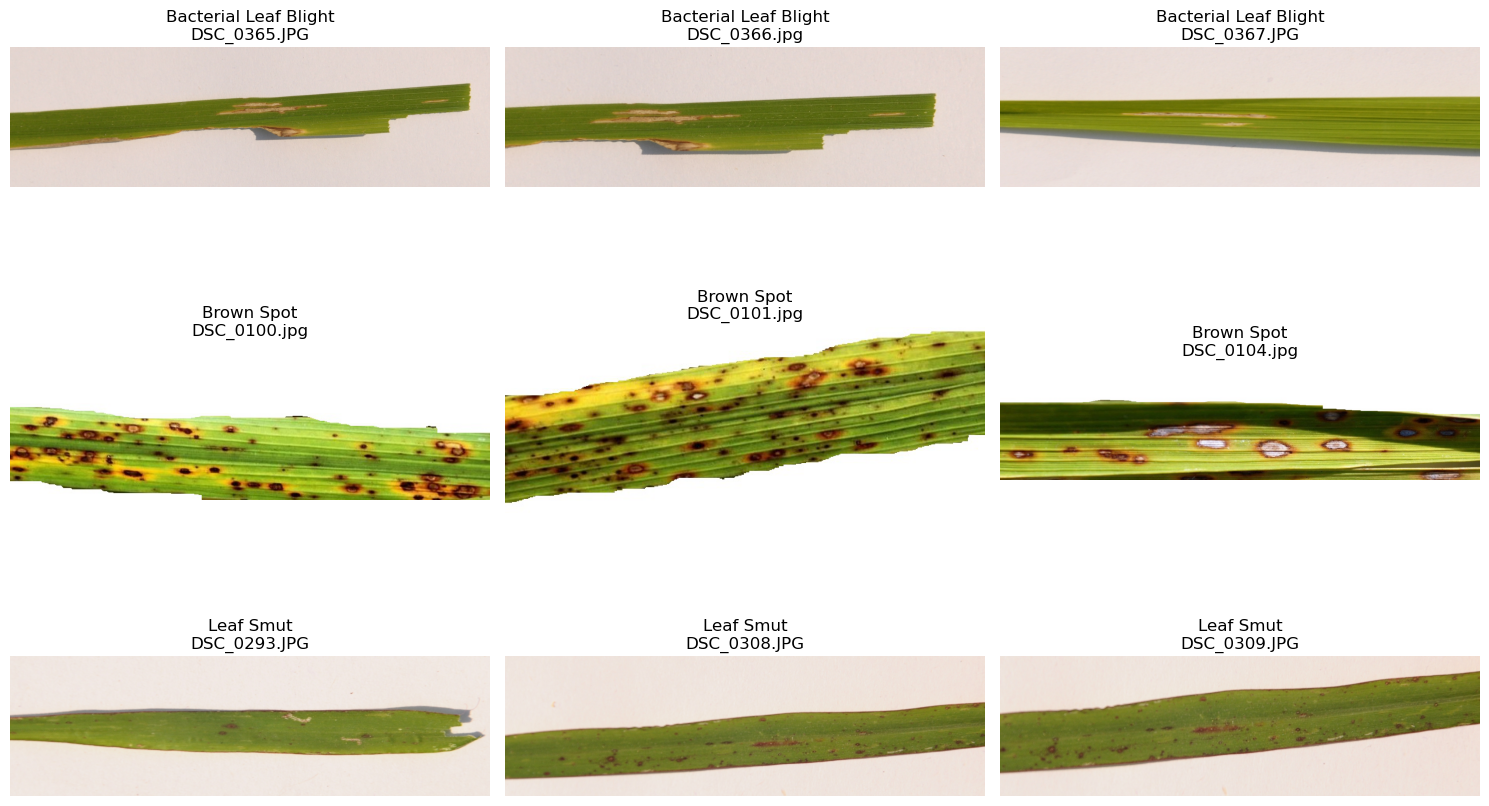

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for row, (class_name, folder_path) in enumerate(class_folders.items()):

    image_files = sorted([
        file for file in folder_path.iterdir()
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ])

    for col, image_path in enumerate(image_files[:3]):

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.copy())

        axes[row, col].set_title(
            f"{class_name}\n{image_path.name}"
        )

        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

### EDA – Image Visualization and Dimension Analysis

**1. Class Distribution**

The dataset contains 119 images distributed across three rice leaf disease categories. Bacterial Leaf Blight and Brown Spot contain 40 images each, while Leaf Smut contains 39 images. The dataset is therefore nearly balanced.

**2. Visual Characteristics**

Sample image visualization revealed differences in the visible appearance of the three disease categories. Brown Spot images commonly show distinct brown lesions, while Leaf Smut images contain scattered dark marks. Bacterial Leaf Blight samples show elongated lesions in some images. However, symptom visibility varies across individual images.

**3. Image Dimensions**

The images have varying resolutions. All 40 Bacterial Leaf Blight images have dimensions of 3081 × 897. Brown Spot and Leaf Smut contain images with multiple dimension combinations.

**4. Aspect Ratio**

Bacterial Leaf Blight images have a consistent aspect ratio of approximately 3.435, whereas Brown Spot and Leaf Smut show greater variation. This indicates the need for careful image resizing during preprocessing to avoid distortion.

**5. Initial Conclusion**

The dataset is almost balanced, but image resolution and aspect-ratio variations need to be considered during preprocessing. Further image-quality and duplicate checks will be performed before model development.

In [12]:
# Image format distribution
print("Image Format Distribution:")
display(image_df["Format"].value_counts())

# Colour mode distribution
print("\nImage Colour Mode Distribution:")
display(image_df["Mode"].value_counts())

# Check these properties class-wise
format_summary = pd.crosstab(
    image_df["Disease"],
    image_df["Format"]
)

mode_summary = pd.crosstab(
    image_df["Disease"],
    image_df["Mode"]
)

print("\nFormat by Disease:")
display(format_summary)

print("\nColour Mode by Disease:")
display(mode_summary)

Image Format Distribution:


Format
JPEG    119
Name: count, dtype: int64


Image Colour Mode Distribution:


Mode
RGB    119
Name: count, dtype: int64


Format by Disease:


Format,JPEG
Disease,
Bacterial Leaf Blight,40
Brown Spot,40
Leaf Smut,39



Colour Mode by Disease:


Mode,RGB
Disease,
Bacterial Leaf Blight,40
Brown Spot,40
Leaf Smut,39


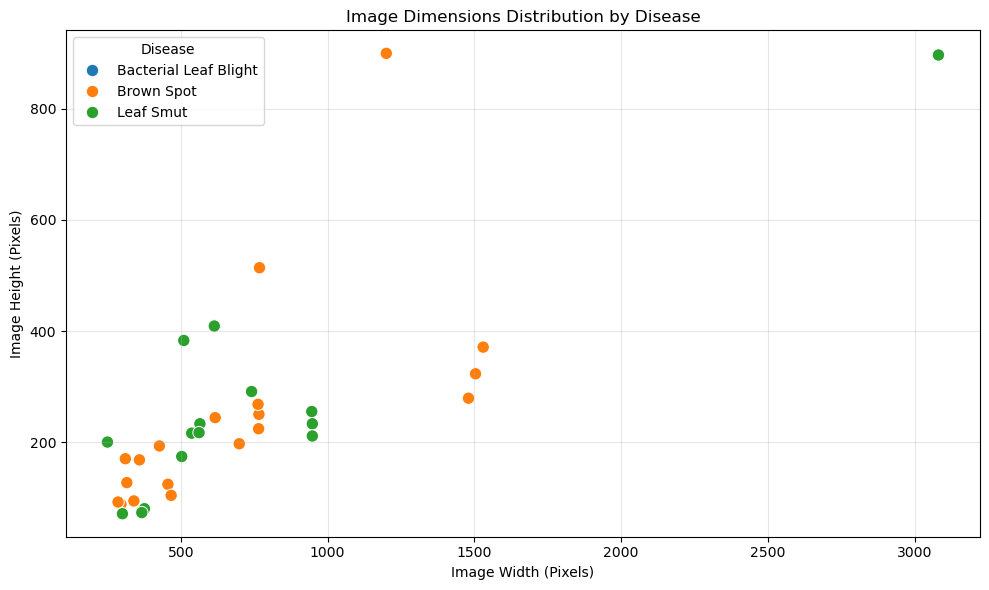

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=image_df,
    x="Width",
    y="Height",
    hue="Disease",
    s=80
)

plt.title("Image Dimensions Distribution by Disease")
plt.xlabel("Image Width (Pixels)")
plt.ylabel("Image Height (Pixels)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
import hashlib

def calculate_image_hash(image_path):
    hash_object = hashlib.md5()

    with open(image_path, "rb") as file:
        for chunk in iter(lambda: file.read(4096), b""):
            hash_object.update(chunk)

    return hash_object.hexdigest()


image_df["File Path"] = image_df.apply(
    lambda row: str(class_folders[row["Disease"]] / row["Filename"]),
    axis=1
)

image_df["Image Hash"] = image_df["File Path"].apply(
    calculate_image_hash
)

duplicate_images = image_df[
    image_df.duplicated(subset="Image Hash", keep=False)
].sort_values("Image Hash")

print("Number of duplicate image records:", len(duplicate_images))

display(duplicate_images[["Disease", "Filename", "Image Hash"]])

Number of duplicate image records: 0


,Disease,Filename,Image Hash


### EDA – Image Dimension Distribution and Duplicate Analysis

**1. Image Dimension Distribution**

The scatter plot indicates significant variation in image dimensions across the dataset. All 40 Bacterial Leaf Blight images have identical dimensions of 3081 × 897. Brown Spot and Leaf Smut contain images with multiple dimension combinations.

**2. Class-wise Resolution Variation**

Among the Brown Spot images, 21 have dimensions of 3081 × 897, while the remaining 19 have different dimensions. Similarly, 24 Leaf Smut images have dimensions of 3081 × 897, while the remaining 15 have varying resolutions.

**3. Duplicate Image Detection**

An exact duplicate check using MD5 hashing identified zero duplicate image files across the dataset.

**4. Preprocessing Implications**

Due to the variation in image dimensions and aspect ratios, image resizing will be required before model training. Aspect-ratio-preserving resizing will be considered to avoid distorting the rice leaf images.

**5. Conclusion**

The dataset contains varied image resolutions but no byte-identical duplicates were detected. Consistent image preprocessing will be important to ensure reliable model training and evaluation.

In [15]:
# Verify that every image can be fully decoded

corrupted_images = []

for class_name, folder_path in class_folders.items():

    image_files = [
        file for file in folder_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    for image_path in image_files:

        try:
            with Image.open(image_path) as img:
                img.verify()

            # Reopen and fully load the image
            with Image.open(image_path) as img:
                img.load()

        except Exception as e:

            corrupted_images.append({
                "Disease": class_name,
                "Filename": image_path.name,
                "Error": str(e)
            })

print("Total corrupted/unreadable images:", len(corrupted_images))

if corrupted_images:
    display(pd.DataFrame(corrupted_images))
else:
    print("All images are readable.")

Total corrupted/unreadable images: 0
All images are readable.


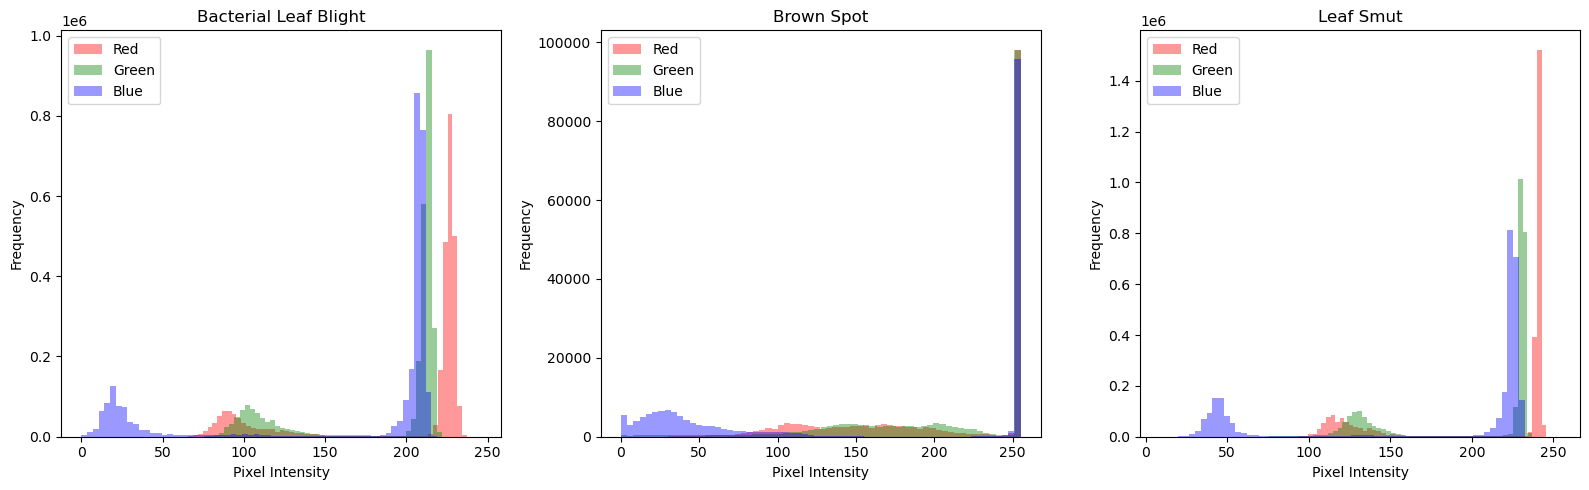

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (class_name, folder_path) in zip(
    axes, class_folders.items()
):

    image_files = sorted([
        file for file in folder_path.iterdir()
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ])

    with Image.open(image_files[0]) as img:
        rgb_image = np.array(img.convert("RGB"))

    for channel, color, label in [
        (0, "red", "Red"),
        (1, "green", "Green"),
        (2, "blue", "Blue")
    ]:

        ax.hist(
            rgb_image[:, :, channel].ravel(),
            bins=64,
            color=color,
            alpha=0.4,
            label=label
        )

    ax.set_title(class_name)
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

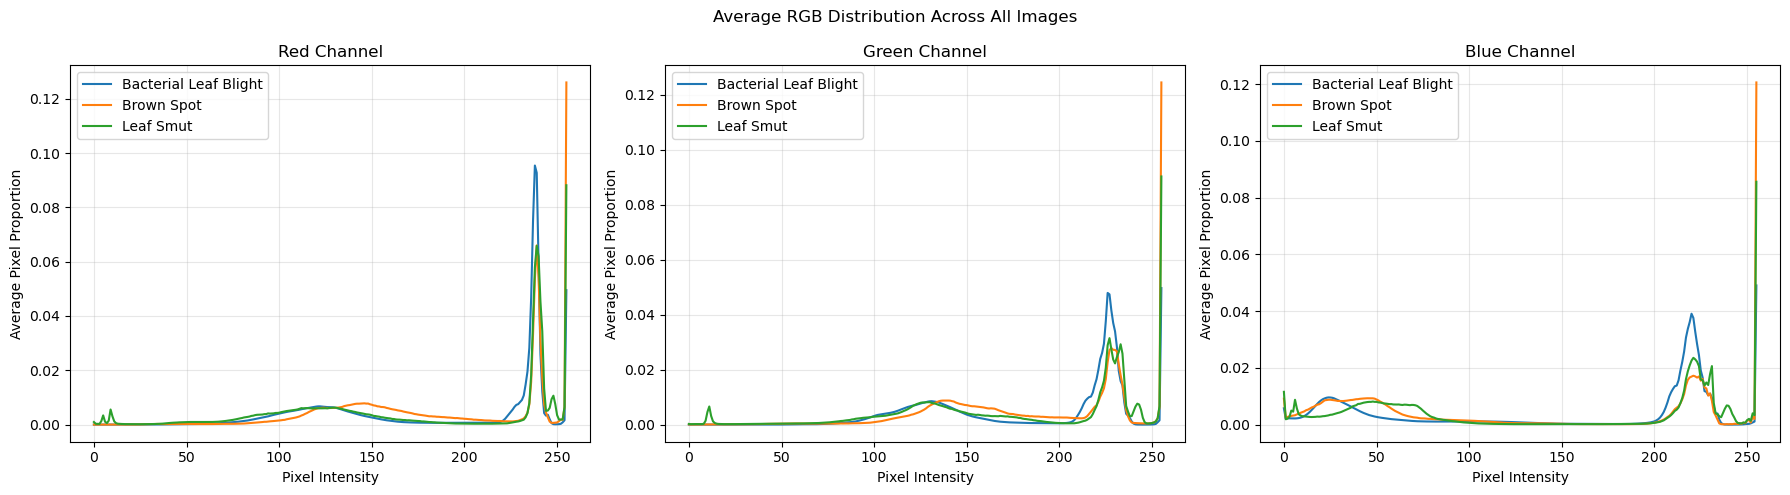

In [17]:
# Calculate the average normalized RGB histogram for each class

channel_names = ["Red", "Green", "Blue"]

class_histograms = {}

for class_name, folder_path in class_folders.items():

    image_files = [
        file for file in folder_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    hist_sum = np.zeros((3, 256))

    for image_path in image_files:

        with Image.open(image_path) as img:
            image = np.asarray(img.convert("RGB"))

        for channel in range(3):

            hist, _ = np.histogram(
                image[:, :, channel],
                bins=256,
                range=(0, 256)
            )

            # Normalize each image's histogram
            hist = hist / hist.sum()

            hist_sum[channel] += hist

    # Average across images in the class
    class_histograms[class_name] = (
        hist_sum / len(image_files)
    )

# Plot class-wise RGB distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for channel, ax in enumerate(axes):

    for class_name, hist_data in class_histograms.items():

        ax.plot(
            range(256),
            hist_data[channel],
            label=class_name
        )

    ax.set_title(f"{channel_names[channel]} Channel")
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Average Pixel Proportion")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Average RGB Distribution Across All Images")
plt.tight_layout()
plt.show()

## Image preprocessing

In [18]:
# Create a master dataset containing image paths and labels

image_records = []

for class_name, folder_path in class_folders.items():

    image_files = [
        file for file in folder_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    for image_path in image_files:

        image_records.append({
            "Image_Path": str(image_path),
            "Disease": class_name
        })

# Create DataFrame
image_dataset = pd.DataFrame(image_records)

# Assign numerical labels
label_map = {
    "Bacterial Leaf Blight": 0,
    "Brown Spot": 1,
    "Leaf Smut": 2
}

image_dataset["Label"] = image_dataset["Disease"].map(label_map)

# Display dataset
display(image_dataset.head())

print("Total Images:", len(image_dataset))
print("\nDisease Distribution:")
display(image_dataset["Disease"].value_counts())

,Image_Path,Disease,Label
0,C:\Users\kalip\Desktop\DS projects\Rice Leaf D...,Bacterial Leaf Blight,0
1,C:\Users\kalip\Desktop\DS projects\Rice Leaf D...,Bacterial Leaf Blight,0
2,C:\Users\kalip\Desktop\DS projects\Rice Leaf D...,Bacterial Leaf Blight,0
3,C:\Users\kalip\Desktop\DS projects\Rice Leaf D...,Bacterial Leaf Blight,0
4,C:\Users\kalip\Desktop\DS projects\Rice Leaf D...,Bacterial Leaf Blight,0


Total Images: 119

Disease Distribution:


Disease
Bacterial Leaf Blight    40
Brown Spot               40
Leaf Smut                39
Name: count, dtype: int64

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
# First split: 70% training and 30% temporary

train_df, temp_df = train_test_split(
    image_dataset,
    test_size=0.30,
    stratify=image_dataset["Label"],
    random_state=42
)

print("Training images:", len(train_df))
print("Temporary images:", len(temp_df))

Training images: 83
Temporary images: 36


In [21]:
# Second split: Divide temporary data equally

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Label"],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 83
Validation images: 18
Testing images: 18


In [22]:
# Display class distribution in each dataset

for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:

    print(f"\n{name} Dataset")

    display(
        df["Disease"].value_counts().sort_index()
    )


Training Dataset


Disease
Bacterial Leaf Blight    28
Brown Spot               28
Leaf Smut                27
Name: count, dtype: int64


Validation Dataset


Disease
Bacterial Leaf Blight    6
Brown Spot               6
Leaf Smut                6
Name: count, dtype: int64


Testing Dataset


Disease
Bacterial Leaf Blight    6
Brown Spot               6
Leaf Smut                6
Name: count, dtype: int64

In [23]:
# Verify that no image is shared between datasets

train_paths = set(train_df["Image_Path"])
val_paths = set(val_df["Image_Path"])
test_paths = set(test_df["Image_Path"])

print("Train and Validation overlap:",
      len(train_paths & val_paths))

print("Train and Test overlap:",
      len(train_paths & test_paths))

print("Validation and Test overlap:",
      len(val_paths & test_paths))

Train and Validation overlap: 0
Train and Test overlap: 0
Validation and Test overlap: 0


## Resizing an Image

In [24]:
from PIL import Image, ImageOps

# Target image dimensions
TARGET_SIZE = (224, 224)

# Resize image while preserving aspect ratio
def resize_with_padding(image_path):

    with Image.open(image_path) as img:

        # Ensure correct orientation and RGB format
        img = ImageOps.exif_transpose(img).convert("RGB")

        # Original dimensions
        original_size = img.size

        # Resize proportionally
        resized_img = ImageOps.contain(
            img,
            TARGET_SIZE,
            method=Image.Resampling.LANCZOS
        )

        # Create a white background canvas
        canvas = Image.new(
            "RGB",
            TARGET_SIZE,
            (255, 255, 255)
        )

        # Calculate padding positions
        x = (TARGET_SIZE[0] - resized_img.width) // 2
        y = (TARGET_SIZE[1] - resized_img.height) // 2

        # Place resized image at the center
        canvas.paste(resized_img, (x, y))

    return canvas, original_size, resized_img.size

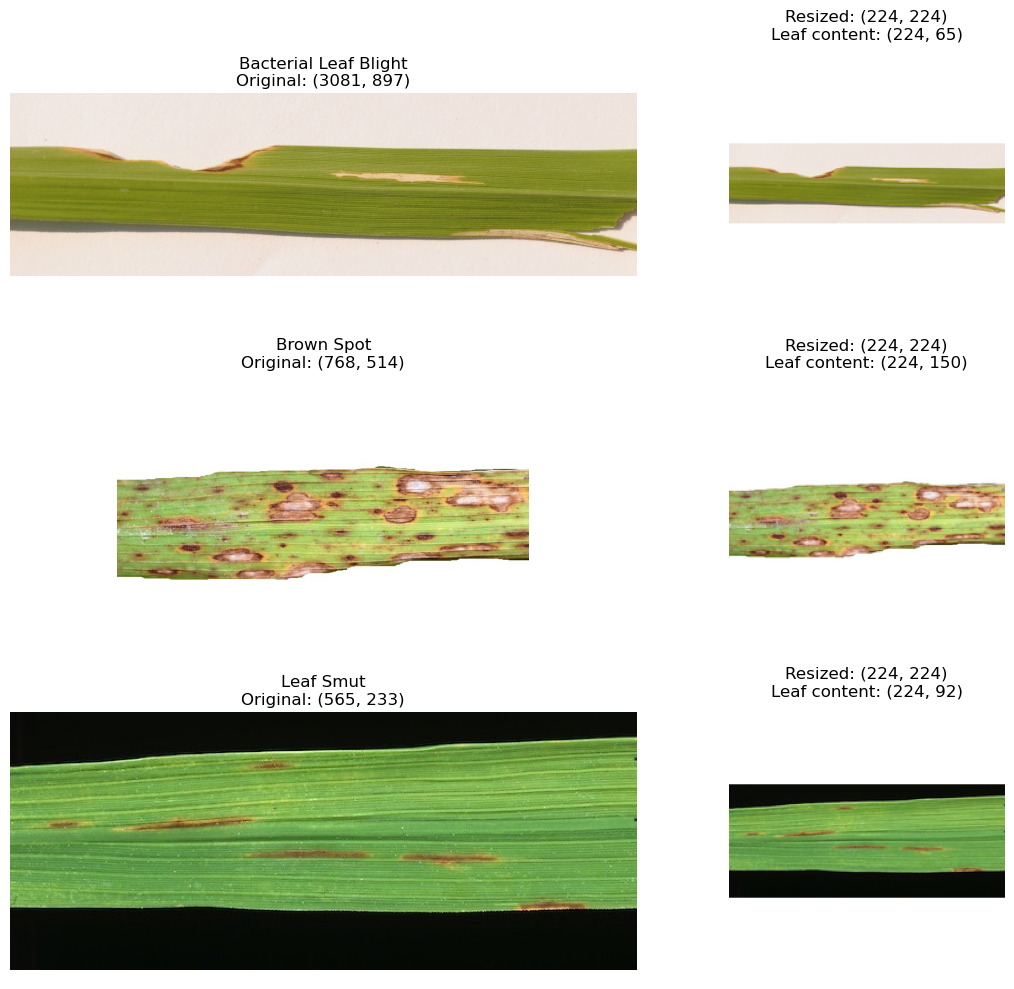

In [25]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for row, class_name in enumerate(class_folders.keys()):

    # Select one training image from each class
    sample_path = train_df[
        train_df["Disease"] == class_name
    ].iloc[0]["Image_Path"]

    # Open original image
    with Image.open(sample_path) as img:
        original_img = ImageOps.exif_transpose(img).convert("RGB")

    # Resize image
    resized_img, original_size, content_size = (
        resize_with_padding(sample_path)
    )

    # Display original image
    axes[row, 0].imshow(original_img)
    axes[row, 0].set_title(
        f"{class_name}\nOriginal: {original_size}"
    )
    axes[row, 0].axis("off")

    # Display resized image
    axes[row, 1].imshow(resized_img)
    axes[row, 1].set_title(
        f"Resized: {TARGET_SIZE}\nLeaf content: {content_size}"
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [26]:
background_data = []

for class_name, folder_path in class_folders.items():

    image_files = [
        file for file in folder_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    for image_path in image_files:

        with Image.open(image_path) as img:
            img_array = np.asarray(img.convert("RGB"))

        height, width, _ = img_array.shape

        # Select border pixels (outer 5% of the image)
        margin = max(1, int(min(height, width) * 0.05))

        border_pixels = np.concatenate([
            img_array[:margin, :, :].reshape(-1, 3),
            img_array[-margin:, :, :].reshape(-1, 3),
            img_array[:, :margin, :].reshape(-1, 3),
            img_array[:, -margin:, :].reshape(-1, 3)
        ])

        # Calculate white and dark pixel proportions
        white_ratio = np.mean(
            np.all(border_pixels >= 230, axis=1)
        )

        dark_ratio = np.mean(
            np.all(border_pixels <= 40, axis=1)
        )

        background_data.append({
            "Disease": class_name,
            "Filename": image_path.name,
            "White Border %": round(white_ratio * 100, 2),
            "Dark Border %": round(dark_ratio * 100, 2)
        })

background_df = pd.DataFrame(background_data)

display(
    background_df.groupby("Disease")[
        ["White Border %", "Dark Border %"]
    ].mean().round(2)
)

,White Border %,Dark Border %
Disease,,
Bacterial Leaf Blight,13.92,0.00
Brown Spot,31.12,0.12
Leaf Smut,36.05,4.78


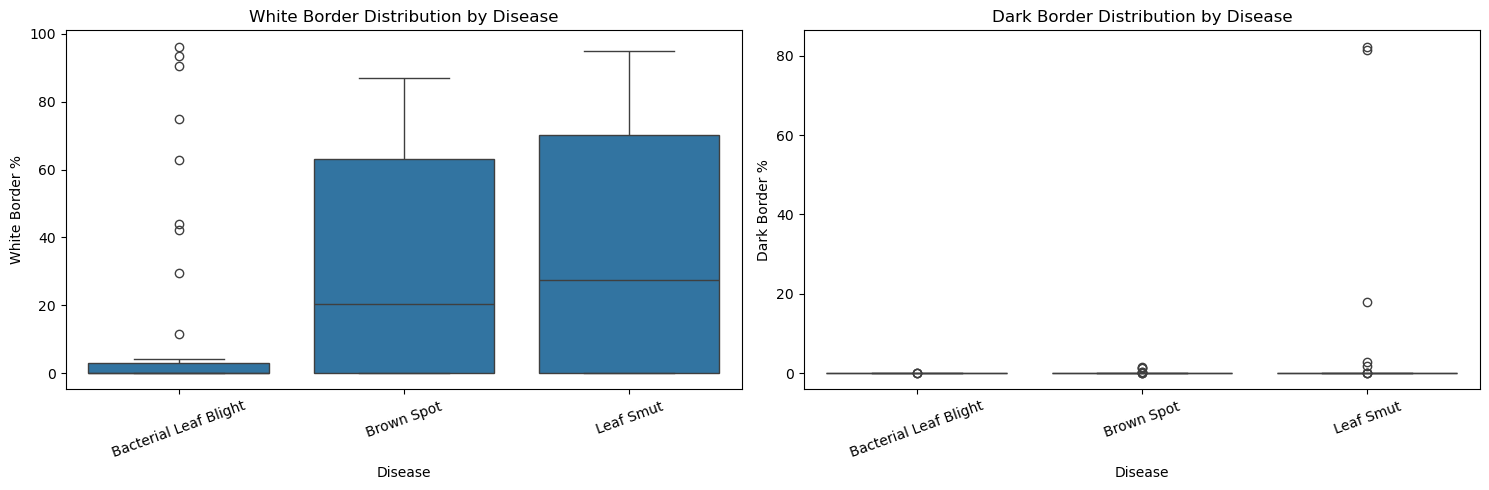

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=background_df,
    x="Disease",
    y="White Border %",
    ax=axes[0]
)

axes[0].set_title("White Border Distribution by Disease")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(
    data=background_df,
    x="Disease",
    y="Dark Border %",
    ax=axes[1]
)

axes[1].set_title("Dark Border Distribution by Disease")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### EDA – Background Characteristics Analysis

The image-border analysis was conducted to investigate background variations across the three disease categories.

The average white-border proportions were 13.92% for Bacterial Leaf Blight, 31.12% for Brown Spot and 36.05% for Leaf Smut.

The corresponding average dark-border proportions were 0.00%, 0.12% and 4.78%, respectively.

These observations indicate variations in image-border characteristics across the dataset. However, the border-based analysis is only an approximate indicator because some border pixels may contain portions of the rice leaves.

Therefore, no automatic background removal was performed at this stage. Original image information will be preserved for the initial model-development experiments.

In [28]:
# Identify images with unusually high border measurements

flagged_images = background_df[
    (background_df["White Border %"] > 80) |
    (background_df["Dark Border %"] > 10)
].sort_values(
    by=["Disease", "Dark Border %"],
    ascending=[True, False]
)

print("Number of flagged images:", len(flagged_images))

display(flagged_images)

Number of flagged images: 16


,Disease,Filename,White Border %,Dark Border %
37,Bacterial Leaf Blight,DSC_0701.jpg,96.23,0.09
36,Bacterial Leaf Blight,DSC_0700.jpg,93.59,0.03
38,Bacterial Leaf Blight,DSC_0702.jpg,90.51,0.00
41,Brown Spot,DSC_0101.jpg,81.86,0.16
51,Brown Spot,DSC_0113.jpg,86.34,0.04
58,Brown Spot,DSC_0121.jpg,86.94,0.00
116,Leaf Smut,DSC_0514.jpg,0.00,82.32
117,Leaf Smut,DSC_0515.jpg,0.00,81.39
118,Leaf Smut,DSC_0516.jpg,42.59,17.94
106,Leaf Smut,DSC_0503.jpg,85.52,2.90


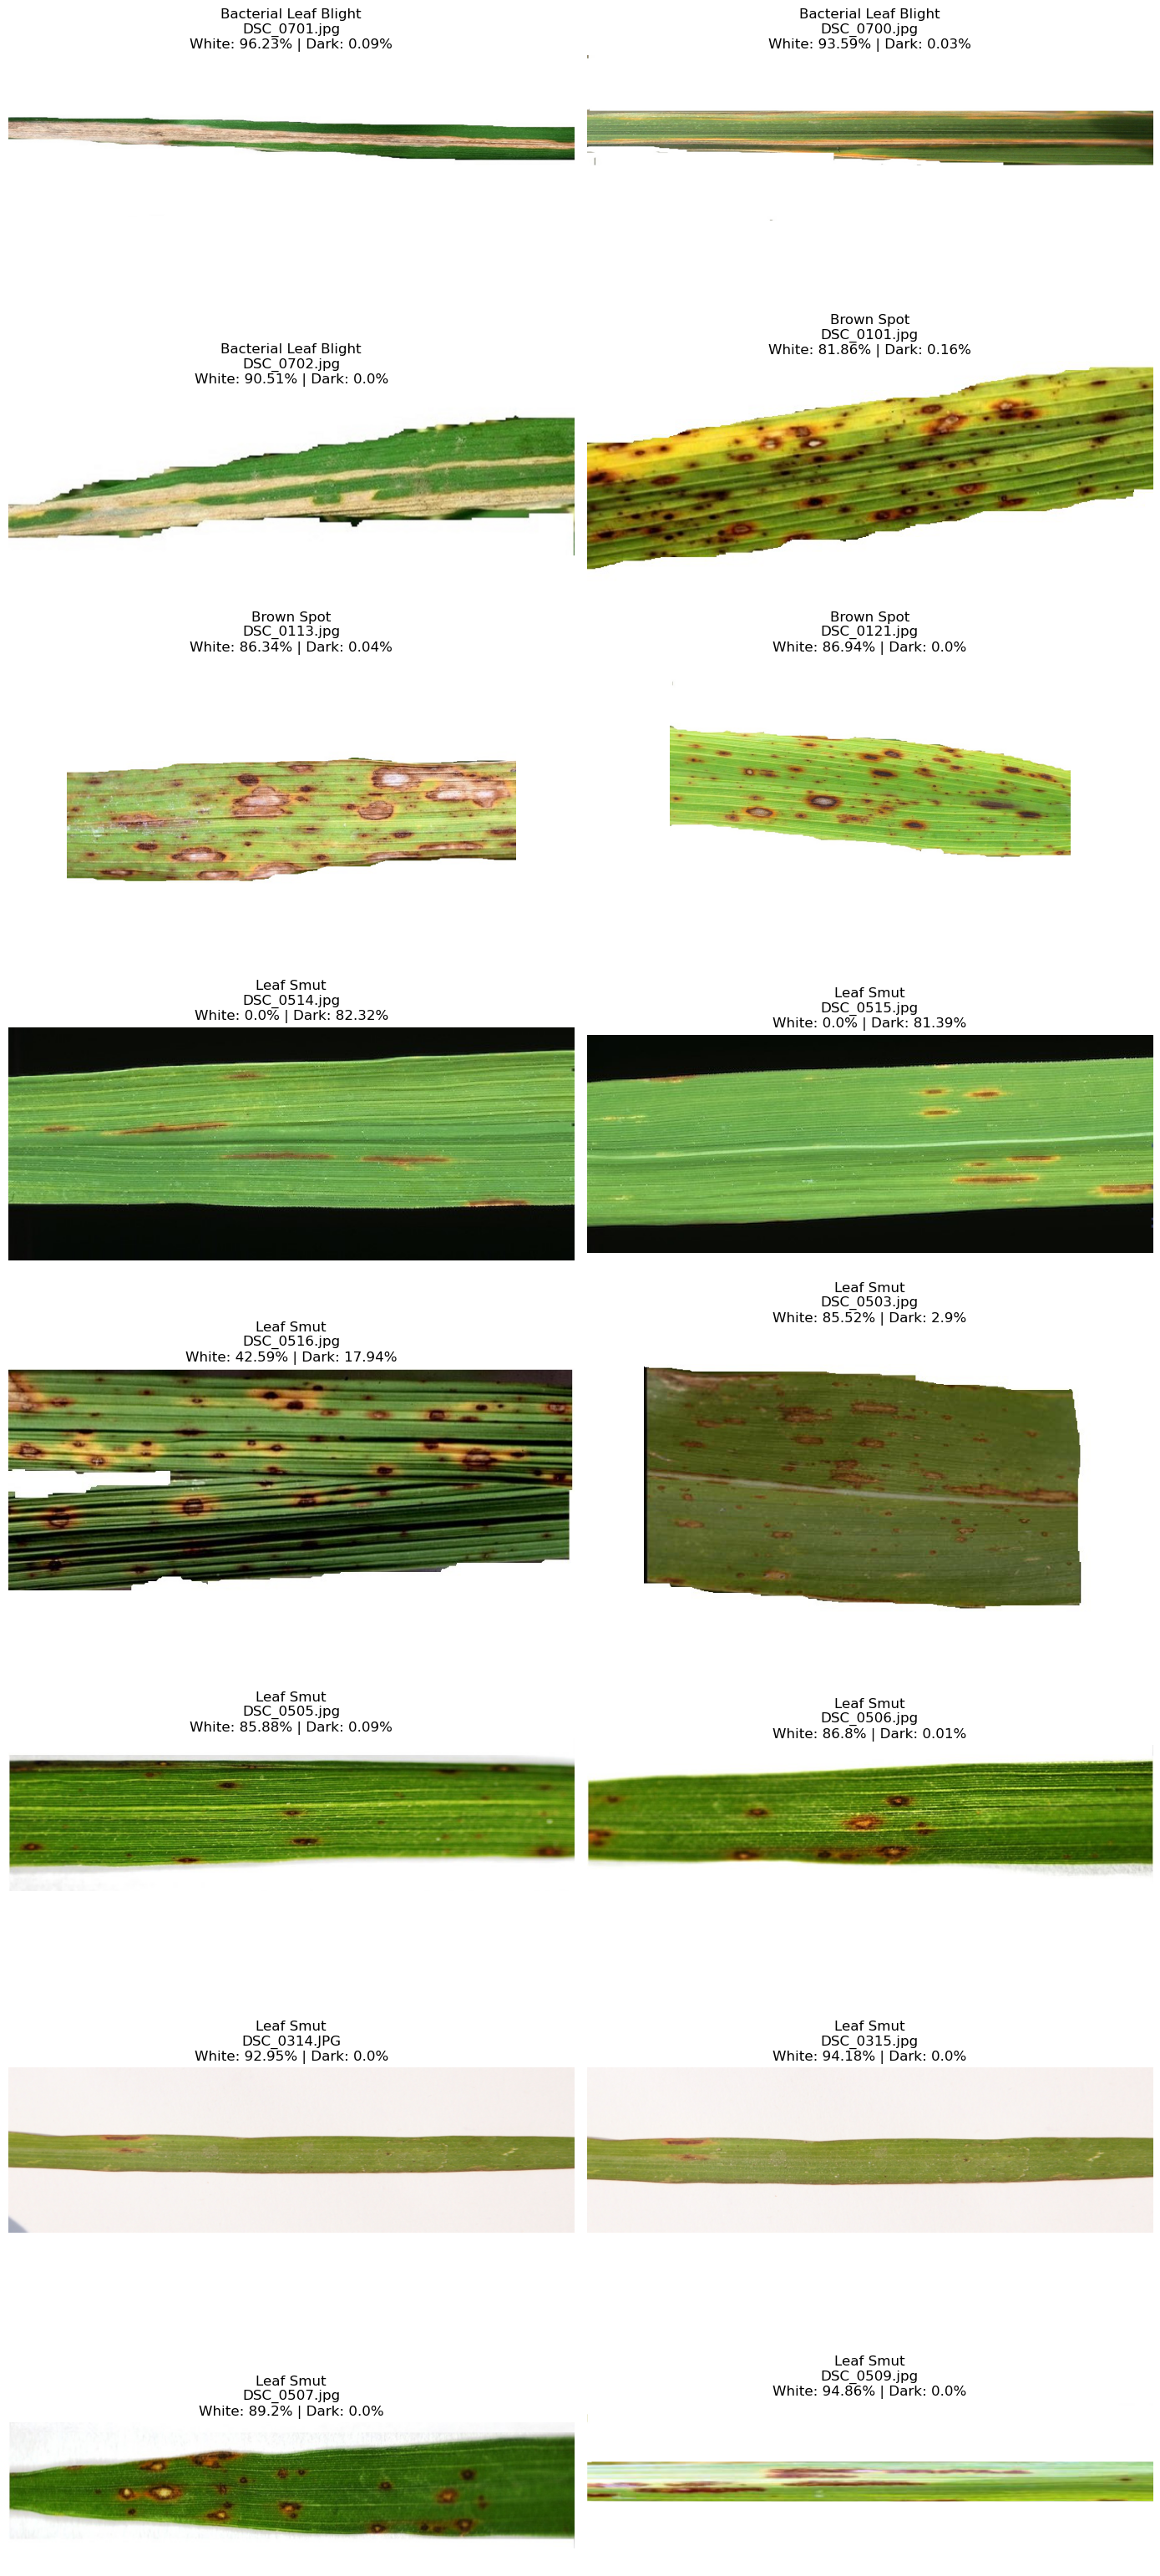

In [29]:
# Display images with unusual background measurements

n = len(flagged_images)

if n > 0:

    fig, axes = plt.subplots(
        (n + 1) // 2, 2,
        figsize=(14, 4 * ((n + 1) // 2))
    )

    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(
        axes,
        flagged_images.iterrows()
    ):

        image_path = (
            class_folders[row["Disease"]] / row["Filename"]
        )

        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f'{row["Disease"]}\n'
            f'{row["Filename"]}\n'
            f'White: {row["White Border %"]}% | '
            f'Dark: {row["Dark Border %"]}%'
        )

        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No images found using the selected thresholds.")

### EDA – Background Distribution Analysis

Boxplot analysis was performed to investigate variations in white and dark border pixels across the three disease categories.

The White Border Distribution showed considerable variation within Brown Spot and Leaf Smut images. Bacterial Leaf Blight images generally exhibited lower white-border proportions, although several high-value outliers were observed.

The Dark Border Distribution showed that most images across all three categories had negligible dark-border proportions. However, a few Leaf Smut images exhibited unusually high dark-border values, with some observations exceeding 80%.

These findings indicate that background and border characteristics are not consistent across all images. Since border measurements can also include actual leaf pixels, they should be treated as approximate indicators rather than definitive background measurements.

No images were removed or modified based on these observations.

### EDA – Visual Inspection of Background Outliers

A threshold-based investigation identified 16 images with unusually high white or dark border percentages.

The flagged images included three Bacterial Leaf Blight images, three Brown Spot images and ten Leaf Smut images.

Visual inspection showed that many flagged images contained recognizable rice leaf structures against predominantly white backgrounds. A few Leaf Smut images contained substantial dark background regions.

One Leaf Smut image, DSC_0516.jpg, also showed multiple leaf strips within the same image and was noted for further inspection.

These observations indicate variation in background characteristics and image composition across the dataset. However, the flagged images were not considered corrupted solely because of their border measurements.

**Decision:** All original images were retained. No background removal or image deletion was performed at this stage. Aspect-ratio-preserving resizing will be used for the initial model experiments, and the possible influence of background variations will be considered during model evaluation.

##  Image Preprocessing
###  Image Resizing and Aspect Ratio Preservation

In [30]:
TARGET_SIZE = (224, 224)

def resize_with_padding(image_path):

    with Image.open(image_path) as img:

        # Correct image orientation and convert to RGB
        img = ImageOps.exif_transpose(img).convert("RGB")

        # Resize while preserving aspect ratio
        resized_img = ImageOps.contain(
            img,
            TARGET_SIZE,
            method=Image.Resampling.LANCZOS
        )

        # Create white background canvas
        canvas = Image.new(
            "RGB",
            TARGET_SIZE,
            (255, 255, 255)
        )

        # Calculate padding positions
        x = (TARGET_SIZE[0] - resized_img.width) // 2
        y = (TARGET_SIZE[1] - resized_img.height) // 2

        # Place resized image on canvas
        canvas.paste(resized_img, (x, y))

    return np.asarray(canvas, dtype=np.uint8)

In [31]:
def prepare_image_dataset(dataframe):

    images = []
    labels = []

    for row in dataframe.itertuples(index=False):

        image = resize_with_padding(row.Image_Path)

        images.append(image)
        labels.append(row.Label)

    X = np.stack(images)
    y = np.asarray(labels, dtype=np.int64)

    return X, y


# Prepare training, validation and testing images

X_train_images, y_train = prepare_image_dataset(train_df)

X_val_images, y_val = prepare_image_dataset(val_df)

X_test_images, y_test = prepare_image_dataset(test_df)

In [32]:
print("Training:", X_train_images.shape)
print("Validation:", X_val_images.shape)
print("Testing:", X_test_images.shape)

print("\nData type:", X_train_images.dtype)

print("\nTraining labels:", np.unique(y_train, return_counts=True))

Training: (83, 224, 224, 3)
Validation: (18, 224, 224, 3)
Testing: (18, 224, 224, 3)

Data type: uint8

Training labels: (array([0, 1, 2]), array([28, 28, 27]))


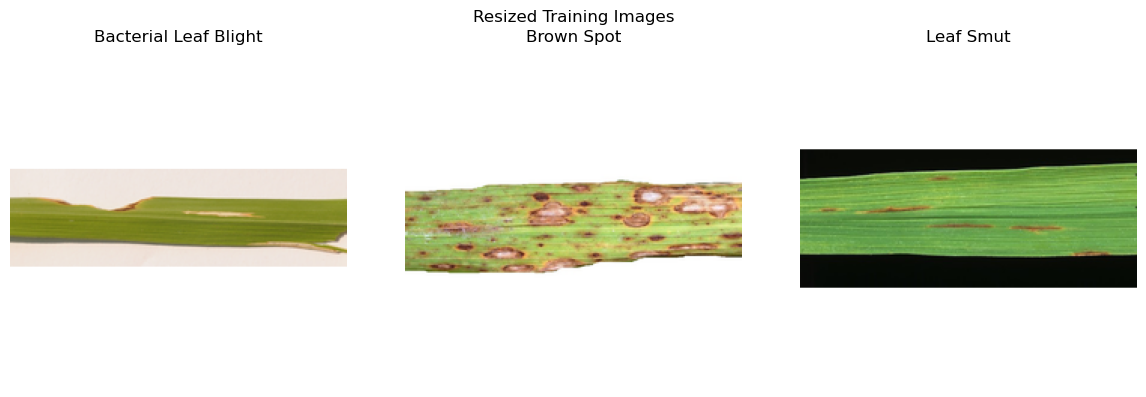

In [33]:
class_names = [
    "Bacterial Leaf Blight",
    "Brown Spot",
    "Leaf Smut"
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for label, ax in enumerate(axes):

    index = np.where(y_train == label)[0][0]

    ax.imshow(X_train_images[index])
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Resized Training Images")
plt.tight_layout()
plt.show()

In [34]:
# Convert pixel values from 0-255 to 0-1

X_train_cnn = X_train_images.astype("float32") / 255.0

X_val_cnn = X_val_images.astype("float32") / 255.0

X_test_cnn = X_test_images.astype("float32") / 255.0

In [35]:
# Check shape, data type and pixel range

for name, data in [
    ("Training", X_train_cnn),
    ("Validation", X_val_cnn),
    ("Testing", X_test_cnn)
]:

    print(f"\n{name} Dataset")
    print("Shape:", data.shape)
    print("Data type:", data.dtype)
    print("Minimum pixel value:", data.min())
    print("Maximum pixel value:", data.max())


Training Dataset
Shape: (83, 224, 224, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0

Validation Dataset
Shape: (18, 224, 224, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0

Testing Dataset
Shape: (18, 224, 224, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0


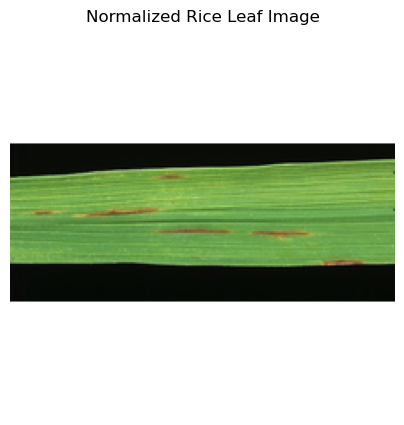

In [36]:
plt.figure(figsize=(5, 5))

plt.imshow(X_train_cnn[0])

plt.title("Normalized Rice Leaf Image")

plt.axis("off")

plt.show()

#  Model 1 – HOG + SVM
###  HOG Feature Extraction

In [37]:
from skimage.feature import hog
from skimage.color import rgb2gray

In [38]:
# HOG configuration

HOG_PARAMETERS = {
    "orientations": 9,
    "pixels_per_cell": (16, 16),
    "cells_per_block": (2, 2),
    "block_norm": "L2-Hys",
    "transform_sqrt": True,
    "feature_vector": True
}


def extract_hog_features(images):

    features = []

    for image in images:

        # Convert RGB image into grayscale
        gray_image = rgb2gray(image)

        # Extract HOG features
        hog_features = hog(
            gray_image,
            **HOG_PARAMETERS
        )

        features.append(hog_features)

    return np.array(features, dtype=np.float32)

In [39]:
# Extract HOG features separately

X_train_hog = extract_hog_features(X_train_images)

X_val_hog = extract_hog_features(X_val_images)

X_test_hog = extract_hog_features(X_test_images)

print("Training HOG shape:", X_train_hog.shape)
print("Validation HOG shape:", X_val_hog.shape)
print("Testing HOG shape:", X_test_hog.shape)

Training HOG shape: (83, 6084)
Validation HOG shape: (18, 6084)
Testing HOG shape: (18, 6084)


In [40]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [41]:
# Create a pipeline with feature scaling and SVM

hog_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

In [42]:
# Train SVM using HOG training features

hog_svm.fit(X_train_hog, y_train)

print("HOG + SVM model training completed.")

HOG + SVM model training completed.


In [43]:
# Predict disease classes using validation data

y_val_pred = hog_svm.predict(X_val_hog)

print("Actual labels:", y_val)
print("Predicted labels:", y_val_pred)

Actual labels: [2 1 0 1 2 0 1 0 2 2 2 0 0 1 0 1 1 2]
Predicted labels: [2 1 0 2 2 0 0 0 1 1 2 0 0 0 0 1 1 2]


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred))

print("Validation Precision (Macro):",
      precision_score(y_val, y_val_pred, average="macro",
                      zero_division=0))

print("Validation Recall (Macro):",
      recall_score(y_val, y_val_pred, average="macro",
                   zero_division=0))

print("Validation F1-Score (Macro):",
      f1_score(y_val, y_val_pred, average="macro",
               zero_division=0))

print("\nClassification Report:\n")

print(classification_report(
    y_val,
    y_val_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

Validation Accuracy: 0.7222222222222222
Validation Precision (Macro): 0.7166666666666668
Validation Recall (Macro): 0.7222222222222222
Validation F1-Score (Macro): 0.70995670995671

Classification Report:

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.75      1.00      0.86         6
           Brown Spot       0.60      0.50      0.55         6
            Leaf Smut       0.80      0.67      0.73         6

             accuracy                           0.72        18
            macro avg       0.72      0.72      0.71        18
         weighted avg       0.72      0.72      0.71        18



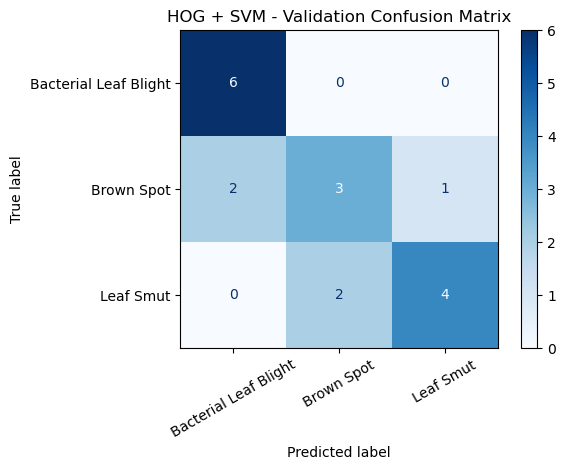

In [45]:
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1, 2]
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

cm_display.plot(cmap="Blues", xticks_rotation=30)

plt.title("HOG + SVM - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [46]:
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)

In [47]:
# Create stratified 5-fold cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [48]:
# Define SVM hyperparameter combinations

param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": [
            "scale",
            "auto",
            0.001,
            0.01,
            0.1
        ]
    }
]

In [49]:
# Search for the best SVM hyperparameters

grid_search = GridSearchCV(
    estimator=hog_svm,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

grid_search.fit(X_train_hog, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}

Best Cross-Validation Macro F1:
0.7681196581196581


In [50]:
# Display top-performing configurations

cv_results = pd.DataFrame(grid_search.cv_results_)

top_results = cv_results[
    [
        "param_classifier__kernel",
        "param_classifier__C",
        "param_classifier__gamma",
        "mean_test_score",
        "std_test_score"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
)

display(top_results.head(10))

,param_classifier__kernel,param_classifier__C,param_classifier__gamma,mean_test_score,std_test_score
14,rbf,10.0,scale,0.768120,0.148690
19,rbf,100.0,scale,0.768120,0.148690
15,rbf,10.0,auto,0.746193,0.156821
20,rbf,100.0,auto,0.734071,0.137941
21,rbf,100.0,0.001,0.723601,0.177392
16,rbf,10.0,0.001,0.723601,0.177392
1,linear,1.0,NaN,0.705466,0.131141
3,linear,100.0,NaN,0.705466,0.131141
2,linear,10.0,NaN,0.705466,0.131141
0,linear,0.1,NaN,0.705466,0.131141


In [51]:
from IPython.display import display as notebook_display

notebook_display(top_results.head(10))

,param_classifier__kernel,param_classifier__C,param_classifier__gamma,mean_test_score,std_test_score
14,rbf,10.0,scale,0.768120,0.148690
19,rbf,100.0,scale,0.768120,0.148690
15,rbf,10.0,auto,0.746193,0.156821
20,rbf,100.0,auto,0.734071,0.137941
21,rbf,100.0,0.001,0.723601,0.177392
16,rbf,10.0,0.001,0.723601,0.177392
1,linear,1.0,NaN,0.705466,0.131141
3,linear,100.0,NaN,0.705466,0.131141
2,linear,10.0,NaN,0.705466,0.131141
0,linear,0.1,NaN,0.705466,0.131141


In [52]:
# Restore display function with a different name
from IPython.display import display as show_table

# Create the results DataFrame
cv_results = pd.DataFrame(grid_search.cv_results_)

# Select and sort the important columns
top_results = cv_results[
    [
        "param_classifier__kernel",
        "param_classifier__C",
        "param_classifier__gamma",
        "mean_test_score",
        "std_test_score"
    ]
].sort_values(
    by="mean_test_score",
    ascending=False
)

# Display top 10 configurations
show_table(top_results.head(10))

,param_classifier__kernel,param_classifier__C,param_classifier__gamma,mean_test_score,std_test_score
14,rbf,10.0,scale,0.768120,0.148690
19,rbf,100.0,scale,0.768120,0.148690
15,rbf,10.0,auto,0.746193,0.156821
20,rbf,100.0,auto,0.734071,0.137941
21,rbf,100.0,0.001,0.723601,0.177392
16,rbf,10.0,0.001,0.723601,0.177392
1,linear,1.0,NaN,0.705466,0.131141
3,linear,100.0,NaN,0.705466,0.131141
2,linear,10.0,NaN,0.705466,0.131141
0,linear,0.1,NaN,0.705466,0.131141


In [53]:
display(top_results.head(10))

,param_classifier__kernel,param_classifier__C,param_classifier__gamma,mean_test_score,std_test_score
14,rbf,10.0,scale,0.768120,0.148690
19,rbf,100.0,scale,0.768120,0.148690
15,rbf,10.0,auto,0.746193,0.156821
20,rbf,100.0,auto,0.734071,0.137941
21,rbf,100.0,0.001,0.723601,0.177392
16,rbf,10.0,0.001,0.723601,0.177392
1,linear,1.0,NaN,0.705466,0.131141
3,linear,100.0,NaN,0.705466,0.131141
2,linear,10.0,NaN,0.705466,0.131141
0,linear,0.1,NaN,0.705466,0.131141


In [54]:
from IPython.display import display as show_table

show_table(top_results.head(10))

,param_classifier__kernel,param_classifier__C,param_classifier__gamma,mean_test_score,std_test_score
14,rbf,10.0,scale,0.768120,0.148690
19,rbf,100.0,scale,0.768120,0.148690
15,rbf,10.0,auto,0.746193,0.156821
20,rbf,100.0,auto,0.734071,0.137941
21,rbf,100.0,0.001,0.723601,0.177392
16,rbf,10.0,0.001,0.723601,0.177392
1,linear,1.0,NaN,0.705466,0.131141
3,linear,100.0,NaN,0.705466,0.131141
2,linear,10.0,NaN,0.705466,0.131141
0,linear,0.1,NaN,0.705466,0.131141


In [55]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}

Best Cross-Validation Macro F1:
0.7681196581196581


In [56]:
# Retrieve the best SVM pipeline

best_hog_svm = grid_search.best_estimator_

# Predict validation images
y_val_tuned = best_hog_svm.predict(X_val_hog)

# Calculate evaluation metrics
print("Tuned Validation Accuracy:",
      accuracy_score(y_val, y_val_tuned))

print("Tuned Validation Precision:",
      precision_score(y_val, y_val_tuned, average="macro",
                      zero_division=0))

print("Tuned Validation Recall:",
      recall_score(y_val, y_val_tuned, average="macro",
                   zero_division=0))

print("Tuned Validation Macro F1:",
      f1_score(y_val, y_val_tuned, average="macro",
               zero_division=0))

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_val_tuned,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

Tuned Validation Accuracy: 0.7777777777777778
Tuned Validation Precision: 0.7746031746031745
Tuned Validation Recall: 0.7777777777777777
Tuned Validation Macro F1: 0.7723387723387724

Classification Report:
                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.86      1.00      0.92         6
           Brown Spot       0.67      0.67      0.67         6
            Leaf Smut       0.80      0.67      0.73         6

             accuracy                           0.78        18
            macro avg       0.77      0.78      0.77        18
         weighted avg       0.77      0.78      0.77        18



### HOG + SVM – Hyperparameter Tuning and Results

**1. Hyperparameter Tuning Methodology**

GridSearchCV was used with Stratified 5-Fold Cross-Validation to identify suitable SVM hyperparameters. Macro F1-score was selected as the scoring metric to evaluate performance across all three disease categories.

**2. Best Hyperparameters**

The selected configuration was:

- Kernel: RBF
- C: 10
- Gamma: scale

The best cross-validation macro F1-score was 0.7681, with a standard deviation of 0.1487 across the five folds.

**3. Baseline vs Tuned Model**

The baseline HOG + SVM model achieved a validation accuracy of 72.22% and a macro F1-score of 70.99%.

After hyperparameter tuning, validation accuracy increased to 77.78%, while macro F1-score improved to 77.23%.

**4. Class-wise Observations**

Bacterial Leaf Blight achieved 100% validation recall. Brown Spot achieved 66.67% recall, while Leaf Smut achieved 66.67% recall.

The model still shows some confusion between Brown Spot and the other disease categories.

**5. Conclusion**

Hyperparameter tuning improved the validation performance of the HOG + SVM classifier. The RBF kernel with C = 10 and gamma = scale was selected based on cross-validation results.

The tuned model will be retained as the HOG + SVM candidate for the overall model comparison.

In [57]:
hog_svm_results = pd.DataFrame({
    "Model": [
        "HOG + SVM (Baseline)",
        "HOG + SVM (Tuned)"
    ],
    "Accuracy": [
        0.7222,
        0.7778
    ],
    "Precision": [
        0.7167,
        0.7746
    ],
    "Recall": [
        0.7222,
        0.7778
    ],
    "Macro F1": [
        0.7100,
        0.7723
    ]
})

show_table(hog_svm_results)

,Model,Accuracy,Precision,Recall,Macro F1
0,HOG + SVM (Baseline),0.7222,0.7167,0.7222,0.7100
1,HOG + SVM (Tuned),0.7778,0.7746,0.7778,0.7723


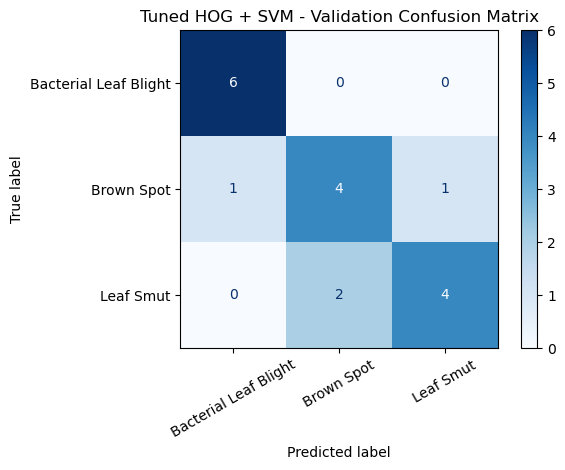

In [58]:
cm_tuned = confusion_matrix(
    y_val,
    y_val_tuned,
    labels=[0, 1, 2]
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=class_names
)

cm_display.plot(cmap="Blues", xticks_rotation=30)

plt.title("Tuned HOG + SVM - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

#  Model 2 – Custom Convolutional Neural Network (CNN)
### Import Libraries

In [59]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Ensure reproducible experiments
tf.keras.utils.set_random_seed(42)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [60]:
import sys

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

Python Version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Python Executable: C:\Users\kalip\anaconda3\python.exe


In [61]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [62]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("TensorFlow Available:", True)

print("Available Devices:",
      tf.config.list_physical_devices())

TensorFlow Version: 2.21.0
TensorFlow Available: True
Available Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [63]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [64]:
cnn_model = keras.Sequential([

    # Input layer
    layers.Input(shape=(224, 224, 3)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Feature aggregation
    layers.GlobalAveragePooling2D(),

    # Classification layers
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),

    # Output layer for three diseases
    layers.Dense(3, activation="softmax")
])

In [65]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

In [66]:
# Compile the CNN model

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully.")

CNN model compiled successfully.


In [67]:
# Configure callbacks to control training

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.000001,
    verbose=1
)

In [68]:
# Train the Custom CNN

cnn_history = cnn_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=50,
    batch_size=8,
    callbacks=[early_stopping, reduce_lr],
    shuffle=True,
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/step - accuracy: 0.3614 - loss: 1.1009 - val_accuracy: 0.3333 - val_loss: 1.0996 - learning_rate: 0.0010
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 0.3373 - loss: 1.1040 - val_accuracy: 0.3333 - val_loss: 1.0980 - learning_rate: 0.0010
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.3253 - loss: 1.1113 - val_accuracy: 0.3333 - val_loss: 1.0967 - learning_rate: 0.0010
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 0.2651 - loss: 1.1022 - val_accuracy: 0.6667 - val_loss: 1.0953 - learning_rate: 0.0010
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - accuracy: 0.3614 - loss: 1.0990 - val_accuracy: 0.3333 - val_loss: 1.0920 - learning_rate: 0.0010
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.3012 - loss: 1.0969 - val_accuracy: 0.4444 - val_loss: 1.0912 - learning_rate: 0.0010
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.4578 - loss: 1.0891 - v

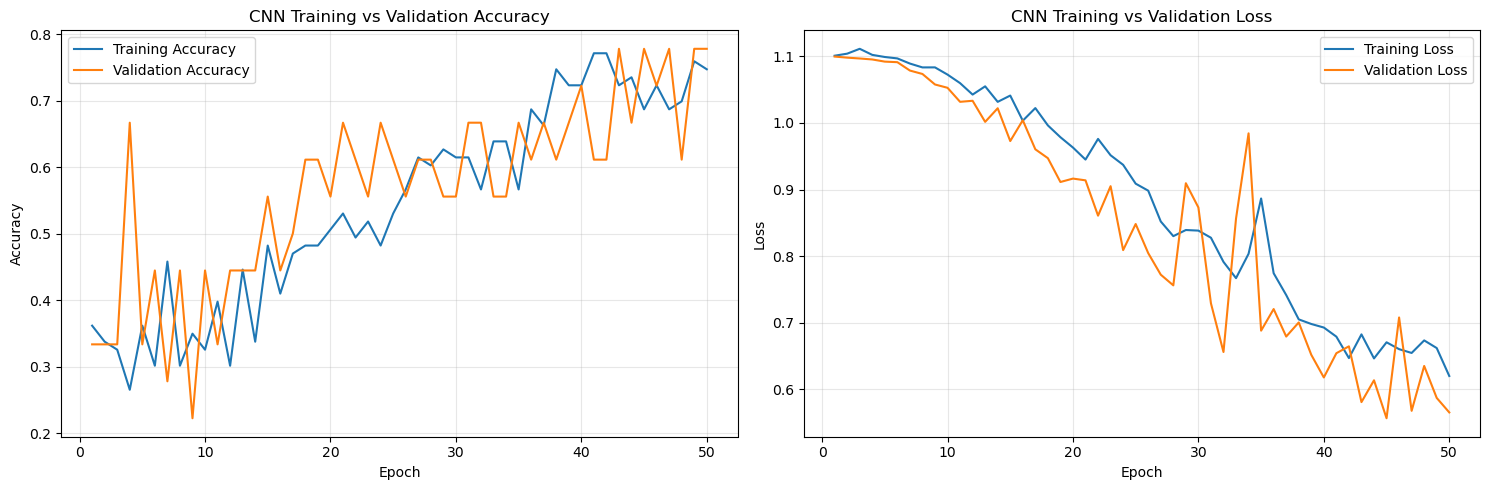

In [69]:
history = cnn_history.history

epochs = range(1, len(history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy plot
axes[0].plot(
    epochs,
    history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("CNN Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss plot
axes[1].plot(
    epochs,
    history["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("CNN Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [70]:
# Evaluate restored best CNN weights

cnn_val_loss, cnn_val_accuracy = cnn_model.evaluate(
    X_val_cnn,
    y_val,
    verbose=0
)

print("CNN Validation Accuracy:", cnn_val_accuracy)
print("CNN Validation Loss:", cnn_val_loss)

CNN Validation Accuracy: 0.7777777910232544
CNN Validation Loss: 0.556520938873291


In [71]:
# Generate probability predictions

cnn_val_probabilities = cnn_model.predict(
    X_val_cnn,
    verbose=0
)

# Convert probabilities into predicted class labels

y_val_cnn_pred = np.argmax(
    cnn_val_probabilities,
    axis=1
)

print("Actual Labels:", y_val)
print("Predicted Labels:", y_val_cnn_pred)

Actual Labels: [2 1 0 1 2 0 1 0 2 2 2 0 0 1 0 1 1 2]
Predicted Labels: [2 1 0 1 1 1 0 0 2 2 2 1 0 1 0 1 1 2]


In [72]:
print("CNN Validation Classification Report:\n")

print(
    classification_report(
        y_val,
        y_val_cnn_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

print(
    "Macro F1-score:",
    f1_score(
        y_val,
        y_val_cnn_pred,
        average="macro"
    )
)

CNN Validation Classification Report:

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.80      0.67      0.73         6
           Brown Spot       0.62      0.83      0.71         6
            Leaf Smut       1.00      0.83      0.91         6

             accuracy                           0.78        18
            macro avg       0.81      0.78      0.78        18
         weighted avg       0.81      0.78      0.78        18

Macro F1-score: 0.7835497835497836


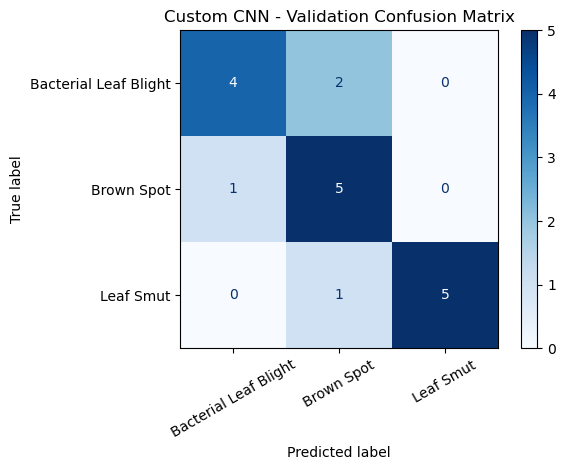

In [73]:
cnn_cm = confusion_matrix(
    y_val,
    y_val_cnn_pred,
    labels=[0, 1, 2]
)

cnn_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cnn_cm,
    display_labels=class_names
)

cnn_cm_display.plot(cmap="Blues", xticks_rotation=30)

plt.title("Custom CNN - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [74]:
model_comparison = pd.DataFrame([
    {
        "Model": "HOG + SVM (Tuned)",
        "Accuracy": 0.7778,
        "Precision": 0.7746,
        "Recall": 0.7778,
        "Macro F1": 0.7723
    },
    {
        "Model": "Custom CNN (Baseline)",
        "Accuracy": 0.7778,
        "Precision": 0.8083,
        "Recall": 0.7778,
        "Macro F1": 0.7835
    }
])

show_table(model_comparison)

,Model,Accuracy,Precision,Recall,Macro F1
0,HOG + SVM (Tuned),0.7778,0.7746,0.7778,0.7723
1,Custom CNN (Baseline),0.7778,0.8083,0.7778,0.7835


### Custom CNN – Model Evaluation and Observations

The Custom CNN achieved a validation accuracy of 77.78% and a macro F1-score of 78.35%.

The model correctly classified 14 out of 18 validation images.

Class-wise evaluation showed that Leaf Smut achieved the highest F1-score of approximately 91%, followed by Bacterial Leaf Blight at 73% and Brown Spot at 71%.

The training and validation loss curves showed an overall downward trend, indicating that the model learned useful patterns from the training images. However, validation accuracy fluctuated due to the small validation dataset.

Early Stopping restored the model weights from epoch 45, which achieved the lowest validation loss of approximately 0.5565.

**Baseline model comparison:** The tuned HOG + SVM and Custom CNN achieved the same validation accuracy of 77.78%. However, the Custom CNN achieved a slightly higher macro F1-score of 78.35%, compared with 77.23% for HOG + SVM.

The CNN will be retained as the baseline deep learning model for further experiments.

##  Custom CNN – Data Augmentation Experiment
### Define Data Augmentation Techniques

In [77]:
data_augmentation = keras.Sequential([

    layers.RandomFlip(
        "horizontal",
        seed=42
    ),

    layers.RandomRotation(
        factor=0.03,
        fill_mode="nearest",
        seed=43
    ),

    layers.RandomZoom(
        height_factor=0.05,
        width_factor=None,
        fill_mode="nearest",
        seed=44
    ),

    layers.RandomTranslation(
        height_factor=0.03,
        width_factor=0.03,
        fill_mode="nearest",
        seed=45
    )

], name="data_augmentation")

print("Improved augmentation pipeline created.")

Improved augmentation pipeline created.


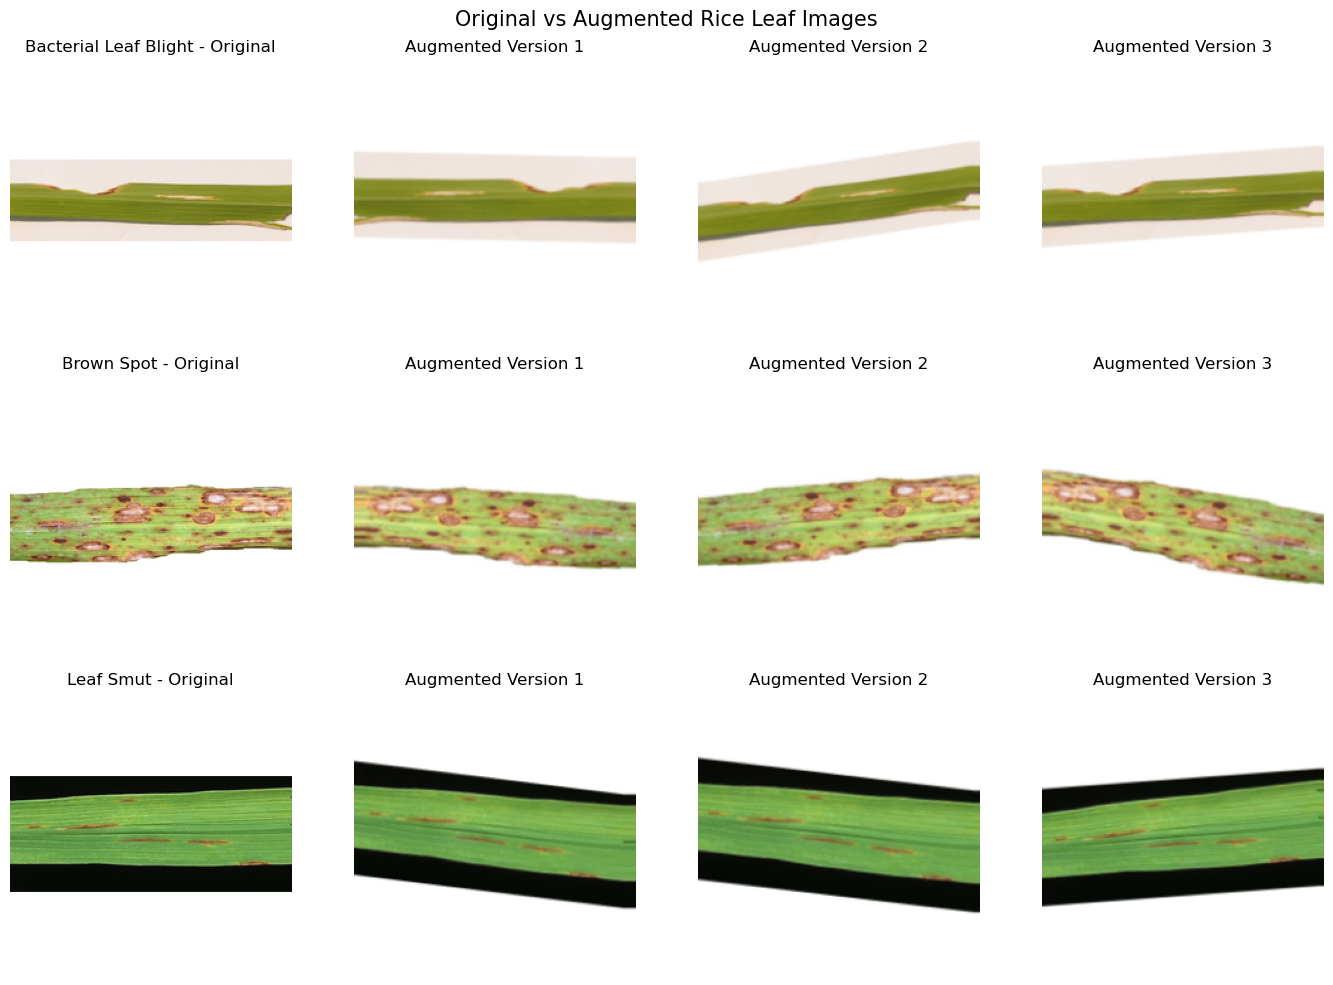

In [78]:
# Select one training image from each disease

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for row, label in enumerate([0, 1, 2]):

    # Get one image belonging to the current class
    sample_index = np.where(y_train == label)[0][0]

    original_image = X_train_cnn[sample_index]

    # Display original image
    axes[row, 0].imshow(original_image)
    axes[row, 0].set_title(
        f"{class_names[label]} - Original"
    )
    axes[row, 0].axis("off")

    # Generate three augmented versions
    sample_batch = tf.expand_dims(
        original_image, axis=0
    )

    for col in range(1, 4):

        augmented_image = data_augmentation(
            sample_batch,
            training=True
        )[0].numpy()

        axes[row, col].imshow(
            np.clip(augmented_image, 0, 1)
        )

        axes[row, col].set_title(
            f"Augmented Version {col}"
        )

        axes[row, col].axis("off")

plt.suptitle(
    "Original vs Augmented Rice Leaf Images",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [79]:
# Set random seed
tf.keras.utils.set_random_seed(42)

# Create CNN with data augmentation
cnn_aug_model = keras.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Feature aggregation
    layers.GlobalAveragePooling2D(),

    # Classification layers
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),

    # Output layer
    layers.Dense(3, activation="softmax")

], name="CNN_With_Augmentation")

print("Augmented CNN architecture created.")

Augmented CNN architecture created.


In [80]:
cnn_aug_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN compiled successfully.")

Augmented CNN compiled successfully.


In [81]:
cnn_aug_model.summary()

Model: "CNN_With_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

In [82]:
early_stopping_aug = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_aug = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.000001,
    verbose=1
)

In [83]:
cnn_aug_history = cnn_aug_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=50,
    batch_size=8,
    callbacks=[
        early_stopping_aug,
        reduce_lr_aug
    ],
    shuffle=True,
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 149ms/step - accuracy: 0.3735 - loss: 1.0986 - val_accuracy: 0.3333 - val_loss: 1.0988 - learning_rate: 0.0010
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.3614 - loss: 1.0997 - val_accuracy: 0.3333 - val_loss: 1.0988 - learning_rate: 0.0010
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - accuracy: 0.2892 - loss: 1.1135 - val_accuracy: 0.3333 - val_loss: 1.0965 - learning_rate: 0.0010
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.3373 - loss: 1.1048 - val_accuracy: 0.5000 - val_loss: 1.0958 - learning_rate: 0.0010
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - accuracy: 0.3253 - loss: 1.1006 - val_accuracy: 0.3333 - val_loss: 1.0953 - learning_rate: 0.0010
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - accuracy: 0.3012 - loss: 1.0983 - val_accuracy: 0.3333 - val_loss: 1.0935 - learning_rate: 0.0010
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.3133 - loss: 1.0922 - 

In [84]:
early_stopping_aug = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_aug = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.000001,
    verbose=1
)

In [85]:
cnn_aug_history = cnn_aug_model.fit(
    X_train_cnn,
    y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=50,
    batch_size=8,
    callbacks=[
        early_stopping_aug,
        reduce_lr_aug
    ],
    shuffle=True,
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - accuracy: 0.7711 - loss: 0.5864 - val_accuracy: 0.8333 - val_loss: 0.6221 - learning_rate: 2.5000e-04
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 0.7831 - loss: 0.6098 - val_accuracy: 0.7222 - val_loss: 0.5862 - learning_rate: 2.5000e-04
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 0.7711 - loss: 0.6177 - val_accuracy: 0.8333 - val_loss: 0.5667 - learning_rate: 2.5000e-04
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - accuracy: 0.7711 - loss: 0.5810 - val_accuracy: 0.8333 - val_loss: 0.5999 - learning_rate: 2.5000e-04
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 0.7831 - loss: 0.5532 - val_accuracy: 0.8333 - val_loss: 0.5759 - learning_rate: 2.5000e-04
Epoch 6/50
10/11 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.7500 - loss: 0.5763
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.759

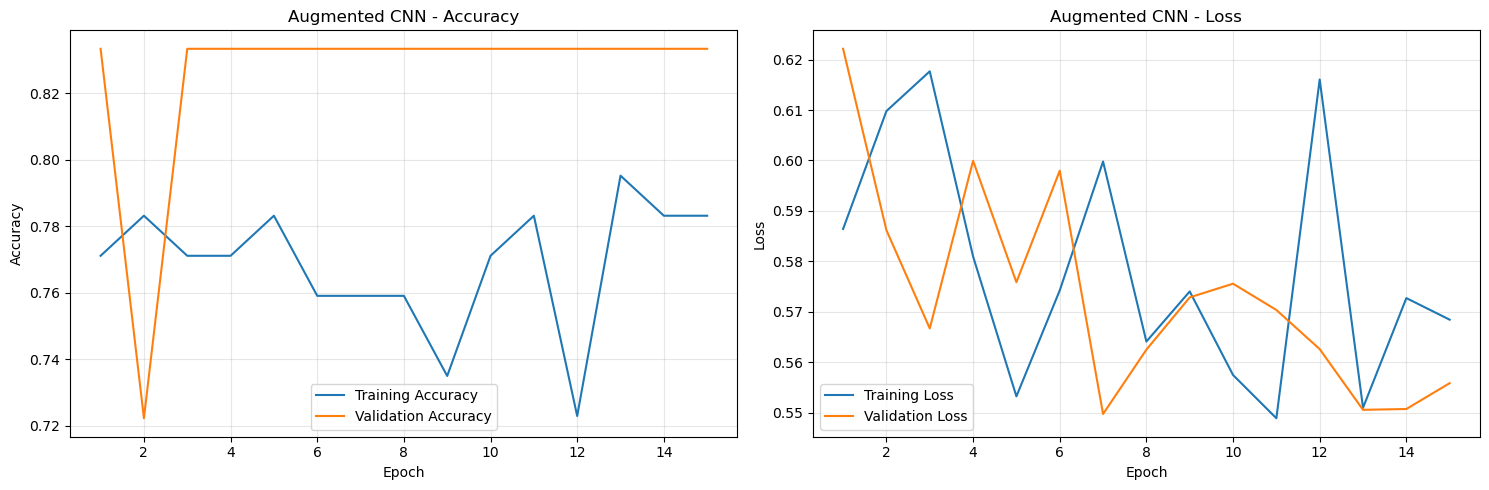

In [86]:
history_aug = cnn_aug_history.history

epochs_aug = range(
    1,
    len(history_aug["accuracy"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy plot
axes[0].plot(
    epochs_aug,
    history_aug["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs_aug,
    history_aug["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("Augmented CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss plot
axes[1].plot(
    epochs_aug,
    history_aug["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs_aug,
    history_aug["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Augmented CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [87]:
cnn_aug_val_loss, cnn_aug_val_accuracy = (
    cnn_aug_model.evaluate(
        X_val_cnn,
        y_val,
        verbose=0
    )
)

print("Augmented CNN Validation Accuracy:",
      cnn_aug_val_accuracy)

print("Augmented CNN Validation Loss:",
      cnn_aug_val_loss)

Augmented CNN Validation Accuracy: 0.8333333134651184
Augmented CNN Validation Loss: 0.5497322678565979


In [88]:
cnn_aug_val_probabilities = cnn_aug_model.predict(
    X_val_cnn,
    verbose=0
)

y_val_aug_pred = np.argmax(
    cnn_aug_val_probabilities,
    axis=1
)

print("Actual Labels:", y_val)
print("Predicted Labels:", y_val_aug_pred)

Actual Labels: [2 1 0 1 2 0 1 0 2 2 2 0 0 1 0 1 1 2]
Predicted Labels: [2 1 0 1 1 0 1 0 2 2 2 1 0 1 0 1 1 0]


In [89]:
print("Augmented CNN Classification Report:\n")

print(
    classification_report(
        y_val,
        y_val_aug_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

print(
    "Macro F1:",
    f1_score(
        y_val,
        y_val_aug_pred,
        average="macro"
    )
)

Augmented CNN Classification Report:

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.83      0.83      0.83         6
           Brown Spot       0.75      1.00      0.86         6
            Leaf Smut       1.00      0.67      0.80         6

             accuracy                           0.83        18
            macro avg       0.86      0.83      0.83        18
         weighted avg       0.86      0.83      0.83        18

Macro F1: 0.8301587301587302


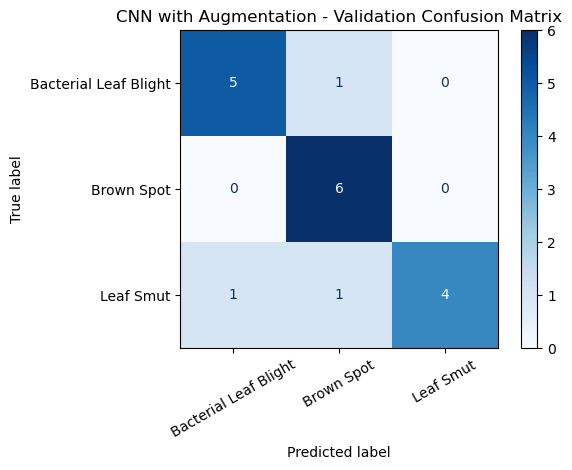

In [90]:
cnn_aug_cm = confusion_matrix(
    y_val,
    y_val_aug_pred,
    labels=[0, 1, 2]
)

cnn_aug_display = ConfusionMatrixDisplay(
    confusion_matrix=cnn_aug_cm,
    display_labels=class_names
)

cnn_aug_display.plot(
    cmap="Blues",
    xticks_rotation=30
)

plt.title("CNN with Augmentation - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [91]:
print("Current optimizer learning rate:",
      float(cnn_aug_model.optimizer.learning_rate.numpy()))

print("\nLearning rates recorded during training:")
print(cnn_aug_history.history["learning_rate"])

Current optimizer learning rate: 3.125000148429535e-05

Learning rates recorded during training:
[0.0002500000118743628, 0.0002500000118743628, 0.0002500000118743628, 0.0002500000118743628, 0.0002500000118743628, 0.0002500000118743628, 0.0001250000059371814, 0.0001250000059371814, 0.0001250000059371814, 0.0001250000059371814, 6.25000029685907e-05, 6.25000029685907e-05, 6.25000029685907e-05, 3.125000148429535e-05, 3.125000148429535e-05]


## Controlled Data Augmentation Experiment

In [93]:

# Set random seeds for reproducibility
tf.keras.utils.set_random_seed(42)

# Create a fresh augmentation pipeline
data_augmentation_v2 = keras.Sequential([

    layers.RandomFlip(
        "horizontal",
        seed=42
    ),

    layers.RandomRotation(
        factor=0.03,
        fill_mode="nearest",
        seed=43
    ),

    layers.RandomZoom(
        height_factor=0.05,
        width_factor=None,
        fill_mode="nearest",
        seed=44
    ),

    layers.RandomTranslation(
        height_factor=0.03,
        width_factor=0.03,
        fill_mode="nearest",
        seed=45
    )

], name="data_augmentation_v2")

print("Fresh augmentation pipeline created successfully.")


Fresh augmentation pipeline created successfully.


In [94]:

# Create a fresh CNN with data augmentation

cnn_aug_model_v2 = keras.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation_v2,

    # Convolution Block 1
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Feature aggregation
    layers.GlobalAveragePooling2D(),

    # Classification layers
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),

    # Three disease classes
    layers.Dense(3, activation="softmax")

], name="CNN_With_Augmentation_Controlled")

print("Fresh augmented CNN created.")


Fresh augmented CNN created.


In [95]:

# Compile the fresh augmented CNN

cnn_aug_model_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Verify initial learning rate
initial_lr = float(
    cnn_aug_model_v2.optimizer.learning_rate.numpy()
)

print("Initial Learning Rate:", initial_lr)

# Verify the learning rate
assert np.isclose(initial_lr, 0.001), (
    "Incorrect initial learning rate!"
)

print("Learning rate verified successfully.")


Initial Learning Rate: 0.0010000000474974513
Learning rate verified successfully.


In [96]:

# Early stopping callback
early_stopping_v2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Learning rate reduction callback
reduce_lr_v2 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.000001,
    verbose=1
)

print("Fresh callbacks configured successfully.")


Fresh callbacks configured successfully.


In [97]:

# Train the controlled augmented CNN

cnn_aug_history_v2 = cnn_aug_model_v2.fit(

    X_train_cnn,
    y_train,

    validation_data=(
        X_val_cnn,
        y_val
    ),

    epochs=50,
    batch_size=8,

    callbacks=[
        early_stopping_v2,
        reduce_lr_v2
    ],

    shuffle=True,
    verbose=1
)


Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 143ms/step - accuracy: 0.3735 - loss: 1.0971 - val_accuracy: 0.3333 - val_loss: 1.0984 - learning_rate: 0.0010
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 0.3373 - loss: 1.1032 - val_accuracy: 0.3333 - val_loss: 1.0979 - learning_rate: 0.0010
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - accuracy: 0.3012 - loss: 1.1152 - val_accuracy: 0.3333 - val_loss: 1.0972 - learning_rate: 0.0010
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.2530 - loss: 1.1036 - val_accuracy: 0.4444 - val_loss: 1.0968 - learning_rate: 0.0010
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.2651 - loss: 1.0991 - val_accuracy: 0.3333 - val_loss: 1.0962 - learning_rate: 0.0010
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - accuracy: 0.3012 - loss: 1.0972 - val_accuracy: 0.3333 - val_loss: 1.0935 - learning_rate: 0.0010
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - accuracy: 0.3373 - loss: 1.0932 - 

In [98]:

print("Learning Rates During Training:")

print(
    cnn_aug_history_v2.history["learning_rate"]
)

print(
    "\nFirst Epoch Learning Rate:",
    cnn_aug_history_v2.history["learning_rate"][0]
)

print(
    "\nNumber of Epochs Completed:",
    len(cnn_aug_history_v2.history["loss"])
)


Learning Rates During Training:
[0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0010000000474974513, 0.0005000000237487257, 0.0005000000237487257, 0.0005000000237487257, 0.0005000000237487257, 0.0005000000237487257, 0.0005000000237487257, 0.0005000000237487257, 0.0005000000237487257, 0.0005000000237487257, 0.0005000000237487257, 0.0005000000237487257, 0

In [99]:

cnn_aug_v2_loss, cnn_aug_v2_accuracy = (
    cnn_aug_model_v2.evaluate(
        X_val_cnn,
        y_val,
        verbose=0
    )
)

print("Validation Accuracy:", cnn_aug_v2_accuracy)
print("Validation Loss:", cnn_aug_v2_loss)


Validation Accuracy: 0.6666666865348816
Validation Loss: 0.6589682698249817


In [100]:

cnn_aug_v2_probabilities = cnn_aug_model_v2.predict(
    X_val_cnn,
    verbose=0
)

y_val_aug_v2_pred = np.argmax(
    cnn_aug_v2_probabilities,
    axis=1
)

print(
    classification_report(
        y_val,
        y_val_aug_v2_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

print(
    "Macro F1:",
    f1_score(
        y_val,
        y_val_aug_v2_pred,
        average="macro"
    )
)


                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.60      0.50      0.55         6
           Brown Spot       0.71      0.83      0.77         6
            Leaf Smut       0.67      0.67      0.67         6

             accuracy                           0.67        18
            macro avg       0.66      0.67      0.66        18
         weighted avg       0.66      0.67      0.66        18

Macro F1: 0.6604506604506604


### Data Augmentation – Controlled CNN Experiment

**Objective:** Evaluate whether data augmentation improves the generalization performance of the Custom CNN.

**Techniques applied:**
- Random horizontal flipping
- Random rotation
- Aspect-ratio-preserving random zoom
- Random translation

Augmentation was applied dynamically to training images only. Validation images were kept unchanged.

**Training Configuration:**

- Initial learning rate: 0.001
- Optimizer: Adam
- Maximum epochs: 50
- Batch size: 8
- Loss function: Sparse Categorical Cross-Entropy
- Early Stopping patience: 8

**Results:**

The controlled augmented CNN achieved a validation accuracy of 66.67% and a macro F1-score of 66.05%. The best validation loss was 0.6590 at epoch 40. Early Stopping restored the model weights from that epoch.

**Comparison with the baseline CNN:**

The baseline CNN achieved 77.78% validation accuracy and a macro F1-score of 78.35%, outperforming the controlled augmented experiment.

Class-wise evaluation showed that Brown Spot performance improved, while Bacterial Leaf Blight and Leaf Smut performance decreased.

**Conclusion:**

Data augmentation did not improve overall validation performance under the current experimental configuration. Although augmentation may provide additional variation to training images, its effectiveness depends on dataset characteristics and transformation settings. Further experimentation may be required to identify more suitable augmentation strategies.

In [101]:
cnn_experiment_results = pd.DataFrame([

    {
        "Experiment": "Baseline CNN",
        "Initial LR": 0.001,
        "Accuracy": 0.7778,
        "Macro F1": 0.7835,
        "Validation Loss": 0.5565
    },

    {
        "Experiment": "Augmented CNN - Exploratory",
        "Initial LR": 0.00025,
        "Accuracy": 0.8333,
        "Macro F1": 0.8302,
        "Validation Loss": 0.5497
    },

    {
        "Experiment": "Augmented CNN - Controlled",
        "Initial LR": 0.001,
        "Accuracy": 0.6667,
        "Macro F1": 0.6605,
        "Validation Loss": 0.6590
    }

])

show_table(cnn_experiment_results)

,Experiment,Initial LR,Accuracy,Macro F1,Validation Loss
0,Baseline CNN,0.00100,0.7778,0.7835,0.5565
1,Augmented CNN - Exploratory,0.00025,0.8333,0.8302,0.5497
2,Augmented CNN - Controlled,0.00100,0.6667,0.6605,0.6590


In [105]:
# Next Model: MobileNetV2

In [102]:
from tensorflow.keras.applications import MobileNetV2

from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input
)

print("MobileNetV2 libraries imported successfully.")

MobileNetV2 libraries imported successfully.


In [103]:
# Convert original resized images to float32
# Apply MobileNetV2-specific preprocessing

X_train_mobilenet = preprocess_input(
    X_train_images.astype("float32")
)

X_val_mobilenet = preprocess_input(
    X_val_images.astype("float32")
)

X_test_mobilenet = preprocess_input(
    X_test_images.astype("float32")
)

In [104]:
for name, data in [
    ("Training", X_train_mobilenet),
    ("Validation", X_val_mobilenet),
    ("Testing", X_test_mobilenet)
]:

    print(f"\n{name} Dataset")
    print("Shape:", data.shape)
    print("Data type:", data.dtype)
    print("Minimum value:", data.min())
    print("Maximum value:", data.max())


Training Dataset
Shape: (83, 224, 224, 3)
Data type: float32
Minimum value: -1.0
Maximum value: 1.0

Validation Dataset
Shape: (18, 224, 224, 3)
Data type: float32
Minimum value: -1.0
Maximum value: 1.0

Testing Dataset
Shape: (18, 224, 224, 3)
Data type: float32
Minimum value: -1.0
Maximum value: 1.0


# Model 3 – MobileNetV2 (Transfer Learning)
### Load Pretrained MobileNetV2

In [106]:
# Load pretrained MobileNetV2

base_model_mnv2 = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("MobileNetV2 loaded successfully.")
print("Output Shape:", base_model_mnv2.output_shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded successfully.
Output Shape: (None, 7, 7, 1280)


In [107]:
# Freeze the pretrained MobileNetV2 backbone

base_model_mnv2.trainable = False

print("Pretrained MobileNetV2 layers frozen.")
print("Total layers:", len(base_model_mnv2.layers))
print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in base_model_mnv2.layers)
)

Pretrained MobileNetV2 layers frozen.
Total layers: 154
Trainable backbone layers: 0


In [108]:
# Define model input
inputs = keras.Input(
    shape=(224, 224, 3)
)

# Extract features using the frozen pretrained backbone
x = base_model_mnv2(
    inputs,
    training=False
)

# Reduce feature map dimensions
x = layers.GlobalAveragePooling2D()(x)

# Add classification layers
x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.4)(x)

# Three-class output
outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

# Create final model
mobilenet_model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="RiceLeaf_MobileNetV2"
)

print("MobileNetV2 classification model created.")

MobileNetV2 classification model created.


In [109]:
mobilenet_model.summary()

Model: "RiceLeaf_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [110]:
# Compile MobileNetV2

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 compiled successfully.")

print(
    "Initial Learning Rate:",
    float(mobilenet_model.optimizer.learning_rate.numpy())
)

MobileNetV2 compiled successfully.
Initial Learning Rate: 0.0010000000474974513


In [111]:
# Early stopping
early_stopping_mnv2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate when validation loss stops improving
reduce_lr_mnv2 = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.000001,
    verbose=1
)

In [112]:
# Train MobileNetV2 with frozen pretrained layers

mobilenet_history = mobilenet_model.fit(
    X_train_mobilenet,
    y_train,
    validation_data=(
        X_val_mobilenet,
        y_val
    ),
    epochs=50,
    batch_size=8,
    callbacks=[
        early_stopping_mnv2,
        reduce_lr_mnv2
    ],
    shuffle=True,
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 305ms/step - accuracy: 0.5301 - loss: 1.1311 - val_accuracy: 0.6667 - val_loss: 0.6870 - learning_rate: 0.0010
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.8193 - loss: 0.4326 - val_accuracy: 0.8333 - val_loss: 0.4255 - learning_rate: 0.0010
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.8795 - loss: 0.3104 - val_accuracy: 0.9444 - val_loss: 0.3076 - learning_rate: 0.0010
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.9398 - loss: 0.2061 - val_accuracy: 0.9444 - val_loss: 0.2680 - learning_rate: 0.0010
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step - accuracy: 0.9639 - loss: 0.1571 - val_accuracy: 0.8889 - val_loss: 0.2574 - learning_rate: 0.0010
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step - accuracy: 0.9639 - loss: 0.1264 - val_accuracy: 0.8889 - val_loss: 0.2376 - learning_rate: 0.0010
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - accuracy: 0.9880 - loss: 0.0902 - 

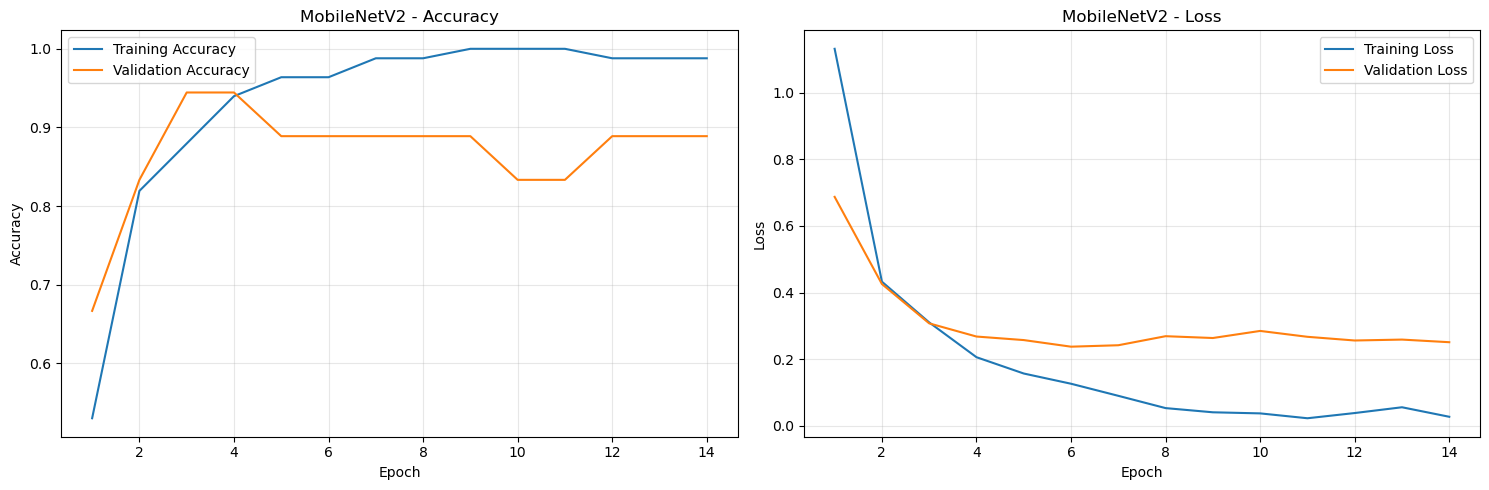

In [113]:
history_mnv2 = mobilenet_history.history

epochs = range(1, len(history_mnv2["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy comparison
axes[0].plot(
    epochs,
    history_mnv2["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    history_mnv2["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("MobileNetV2 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss comparison
axes[1].plot(
    epochs,
    history_mnv2["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs,
    history_mnv2["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("MobileNetV2 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [114]:
mnv2_val_loss, mnv2_val_accuracy = mobilenet_model.evaluate(
    X_val_mobilenet,
    y_val,
    verbose=0
)

print("MobileNetV2 Validation Accuracy:", mnv2_val_accuracy)
print("MobileNetV2 Validation Loss:", mnv2_val_loss)

MobileNetV2 Validation Accuracy: 0.8888888955116272
MobileNetV2 Validation Loss: 0.23760785162448883


In [115]:
mnv2_val_probabilities = mobilenet_model.predict(
    X_val_mobilenet,
    verbose=0
)

y_val_mnv2_pred = np.argmax(
    mnv2_val_probabilities,
    axis=1
)

print("Actual Labels:", y_val)
print("Predicted Labels:", y_val_mnv2_pred)

Actual Labels: [2 1 0 1 2 0 1 0 2 2 2 0 0 1 0 1 1 2]
Predicted Labels: [2 1 0 1 2 0 1 0 2 1 2 0 0 0 0 1 1 2]


In [116]:
print("MobileNetV2 Classification Report:\n")

print(
    classification_report(
        y_val,
        y_val_mnv2_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

print(
    "Macro F1-score:",
    f1_score(
        y_val,
        y_val_mnv2_pred,
        average="macro"
    )
)

print(
    "Macro Precision:",
    precision_score(
        y_val,
        y_val_mnv2_pred,
        average="macro",
        zero_division=0
    )
)

print(
    "Macro Recall:",
    recall_score(
        y_val,
        y_val_mnv2_pred,
        average="macro",
        zero_division=0
    )
)

MobileNetV2 Classification Report:

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.86      1.00      0.92         6
           Brown Spot       0.83      0.83      0.83         6
            Leaf Smut       1.00      0.83      0.91         6

             accuracy                           0.89        18
            macro avg       0.90      0.89      0.89        18
         weighted avg       0.90      0.89      0.89        18

Macro F1-score: 0.8885003885003885
Macro Precision: 0.8968253968253969
Macro Recall: 0.888888888888889


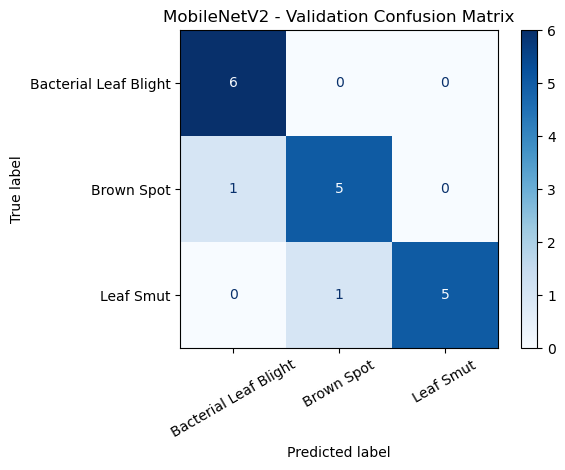

In [117]:
mnv2_cm = confusion_matrix(
    y_val,
    y_val_mnv2_pred,
    labels=[0, 1, 2]
)

mnv2_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=mnv2_cm,
    display_labels=class_names
)

mnv2_cm_display.plot(
    cmap="Blues",
    xticks_rotation=30
)

plt.title("MobileNetV2 - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

### MobileNetV2 – Model Evaluation and Observations

**Approach:** Transfer learning using an ImageNet-pretrained MobileNetV2 backbone with frozen convolutional layers and a newly trained classification head.

**Model configuration:**
- Input image size: 224 × 224 × 3
- Pretrained backbone: MobileNetV2
- Backbone layers: Frozen
- Classification head: Global Average Pooling, Dense (128, ReLU), Dropout (0.4), Dense (3, Softmax)
- Optimizer: Adam
- Initial learning rate: 0.001
- Loss function: Sparse Categorical Crossentropy
- Early stopping: Monitored validation loss with patience of 8 epochs.

**Validation results:**

| Metric | Result |
|---|---:|
| Accuracy | 88.89% |
| Macro Precision | 89.68% |
| Macro Recall | 88.89% |
| Macro F1-score | 88.85% |
| Validation Loss | 0.2376 |

**Observations:**

1. The model achieved strong validation performance after a relatively small number of training epochs.
2. Bacterial Leaf Blight achieved 100% recall, while Leaf Smut achieved 100% precision.
3. Brown Spot and Leaf Smut each had one incorrectly classified validation image.
4. The learning curves indicate possible overfitting because training loss continued decreasing while validation performance stopped improving consistently.
5. Early Stopping restored the weights from epoch 6, which had the lowest validation loss.

**Conclusion:**

MobileNetV2 provided strong results through transfer learning. The frozen pretrained backbone was retained because the dataset is small and the training curves indicate possible overfitting. Its performance will be compared with the other models before selecting a final candidate.

**Limitation:** The validation dataset contains only 18 images. Therefore, the results are preliminary and should not be interpreted as evidence of production-level generalization.

In [119]:
X_train_effnet = X_train_images.astype("float32")
X_val_effnet = X_val_images.astype("float32")
X_test_effnet = X_test_images.astype("float32")

print("Training shape:", X_train_effnet.shape)
print("Validation shape:", X_val_effnet.shape)
print("Testing shape:", X_test_effnet.shape)

print("Data type:", X_train_effnet.dtype)
print("Minimum pixel value:", X_train_effnet.min())
print("Maximum pixel value:", X_train_effnet.max())

Training shape: (83, 224, 224, 3)
Validation shape: (18, 224, 224, 3)
Testing shape: (18, 224, 224, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [120]:
from tensorflow.keras.applications import EfficientNetB0

base_model_effnet = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("EfficientNetB0 loaded successfully.")
print("Total layers:", len(base_model_effnet.layers))
print("Output shape:", base_model_effnet.output_shape)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
EfficientNetB0 loaded successfully.
Total layers: 238
Output shape: (None, 7, 7, 1280)


In [121]:
base_model_effnet.trainable = False

print("EfficientNetB0 backbone frozen.")
print("Trainable:", base_model_effnet.trainable)

EfficientNetB0 backbone frozen.
Trainable: False


In [122]:
inputs = keras.Input(shape=(224, 224, 3))

x = base_model_effnet(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(128, activation="relu")(x)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(3, activation="softmax")(x)

effnet_model = keras.Model(
    inputs,
    outputs,
    name="RiceLeaf_EfficientNetB0"
)

effnet_model.summary()

Model: "RiceLeaf_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 7, 7, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_4           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,213,926 (16.07 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [123]:
effnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNetB0 compiled successfully.")
print("Initial learning rate:",
      float(keras.backend.get_value(
          effnet_model.optimizer.learning_rate
      )))

EfficientNetB0 compiled successfully.
Initial learning rate: 0.0010000000474974513


In [124]:
early_stopping_effnet = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_effnet = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.000001,
    verbose=1
)

In [125]:
effnet_history = effnet_model.fit(
    X_train_effnet,
    y_train,
    validation_data=(X_val_effnet, y_val),
    epochs=50,
    batch_size=8,
    callbacks=[
        early_stopping_effnet,
        reduce_lr_effnet
    ],
    shuffle=True,
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 467ms/step - accuracy: 0.6024 - loss: 0.8131 - val_accuracy: 0.7778 - val_loss: 0.5552 - learning_rate: 0.0010
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 157ms/step - accuracy: 0.7711 - loss: 0.5467 - val_accuracy: 0.8333 - val_loss: 0.4132 - learning_rate: 0.0010
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 149ms/step - accuracy: 0.9036 - loss: 0.3314 - val_accuracy: 0.8889 - val_loss: 0.3090 - learning_rate: 0.0010
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 157ms/step - accuracy: 0.9277 - loss: 0.2748 - val_accuracy: 0.9444 - val_loss: 0.2545 - learning_rate: 0.0010
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 0.9518 - loss: 0.2112 - val_accuracy: 0.9444 - val_loss: 0.2387 - learning_rate: 0.0010
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step - accuracy: 0.9639 - loss: 0.1976 - val_accuracy: 0.9444 - val_loss: 0.1752 - learning_rate: 0.0010
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 0.9639 - loss: 0.1702 -

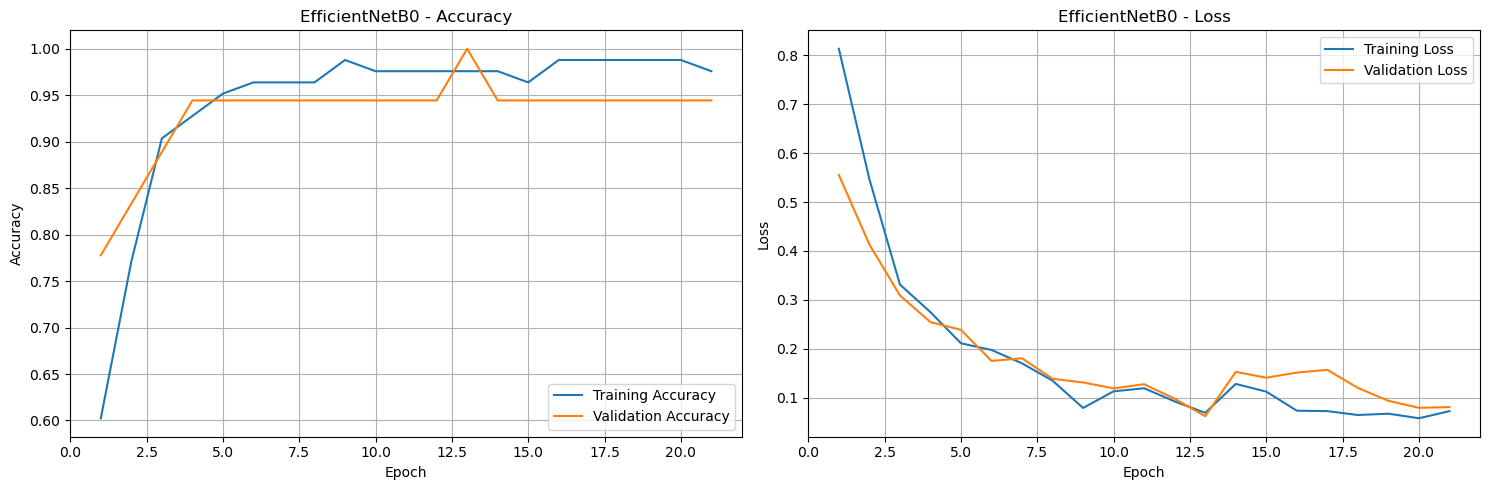

In [126]:
import matplotlib.pyplot as plt

effnet_acc = effnet_history.history["accuracy"]
effnet_val_acc = effnet_history.history["val_accuracy"]
effnet_loss = effnet_history.history["loss"]
effnet_val_loss = effnet_history.history["val_loss"]

epochs_range = range(1, len(effnet_acc) + 1)

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, effnet_acc, label="Training Accuracy")
plt.plot(epochs_range, effnet_val_acc, label="Validation Accuracy")
plt.title("EfficientNetB0 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, effnet_loss, label="Training Loss")
plt.plot(epochs_range, effnet_val_loss, label="Validation Loss")
plt.title("EfficientNetB0 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [127]:
effnet_val_loss, effnet_val_accuracy = effnet_model.evaluate(
    X_val_effnet,
    y_val,
    verbose=0
)

print("EfficientNetB0 Validation Accuracy:", effnet_val_accuracy)
print("EfficientNetB0 Validation Loss:", effnet_val_loss)

EfficientNetB0 Validation Accuracy: 1.0
EfficientNetB0 Validation Loss: 0.062223151326179504


In [128]:
effnet_val_probabilities = effnet_model.predict(
    X_val_effnet,
    verbose=0
)

y_val_effnet_pred = np.argmax(
    effnet_val_probabilities,
    axis=1
)

print("Actual Labels:", y_val)
print("Predicted Labels:", y_val_effnet_pred)

Actual Labels: [2 1 0 1 2 0 1 0 2 2 2 0 0 1 0 1 1 2]
Predicted Labels: [2 1 0 1 2 0 1 0 2 2 2 0 0 1 0 1 1 2]


In [129]:
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

class_names = [
    "Bacterial Leaf Blight",
    "Brown Spot",
    "Leaf Smut"
]

print("EfficientNetB0 Classification Report:\n")

print(
    classification_report(
        y_val,
        y_val_effnet_pred,
        target_names=class_names,
        zero_division=0
    )
)

print("Macro F1-score:",
      f1_score(y_val, y_val_effnet_pred, average="macro"))

print("Macro Precision:",
      precision_score(y_val, y_val_effnet_pred,
                      average="macro", zero_division=0))

print("Macro Recall:",
      recall_score(y_val, y_val_effnet_pred,
                   average="macro", zero_division=0))

EfficientNetB0 Classification Report:

                       precision    recall  f1-score   support

Bacterial Leaf Blight       1.00      1.00      1.00         6
           Brown Spot       1.00      1.00      1.00         6
            Leaf Smut       1.00      1.00      1.00         6

             accuracy                           1.00        18
            macro avg       1.00      1.00      1.00        18
         weighted avg       1.00      1.00      1.00        18

Macro F1-score: 1.0
Macro Precision: 1.0
Macro Recall: 1.0


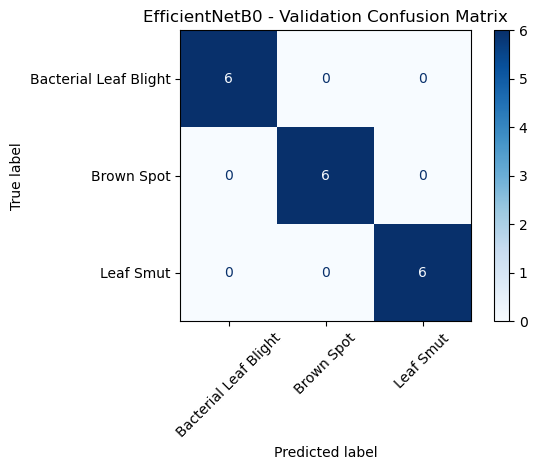

In [130]:
from sklearn.metrics import ConfusionMatrixDisplay

effnet_cm_display = ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_effnet_pred,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

effnet_cm_display.ax_.set_title(
    "EfficientNetB0 - Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

### EfficientNetB0 – Model Evaluation and Observations

**Approach:** Transfer learning using an ImageNet-pretrained EfficientNetB0 backbone with frozen convolutional layers and a newly trained classification head.

**Model configuration:**
- Input image size: 224 × 224 × 3
- Pretrained backbone: EfficientNetB0
- Backbone layers: Frozen
- Classification head: Global Average Pooling, Dense (128, ReLU), Dropout (0.4), Dense (3, Softmax)
- Optimizer: Adam
- Initial learning rate: 0.001
- Loss function: Sparse Categorical Crossentropy
- Early stopping: Monitored validation loss with patience of 8 epochs.
- Training batch size: 8

**Validation results:**

| Metric | Result |
|---|---:|
| Accuracy | 100% |
| Macro Precision | 100% |
| Macro Recall | 100% |
| Macro F1-score | 100% |
| Validation Loss | 0.0622 |

**Observations:**

1. EfficientNetB0 correctly classified all 18 validation images.
2. All three disease categories achieved precision, recall and F1-score of 1.00.
3. The lowest validation loss was achieved at epoch 13.
4. Early Stopping restored the weights from epoch 13.
5. Validation performance fluctuated after the best epoch, indicating that further training did not provide consistent improvements.

**Conclusion:**

EfficientNetB0 achieved the highest validation performance among the evaluated models. It is selected as the leading candidate for final testing and further investigation.

**Limitation:** The validation set contains only 18 images. Therefore, perfect validation performance does not establish reliable performance on larger or independent real-world datasets.

In [131]:
model_comparison_final = pd.DataFrame([
    {
        "Model": "HOG + Tuned SVM",
        "Accuracy": 77.78,
        "Macro Precision": 77.46,
        "Macro Recall": 77.78,
        "Macro F1": 77.23
    },
    {
        "Model": "Custom CNN",
        "Accuracy": 77.78,
        "Macro Precision": 80.67,
        "Macro Recall": 77.78,
        "Macro F1": 78.35
    },
    {
        "Model": "MobileNetV2",
        "Accuracy": 88.89,
        "Macro Precision": 89.68,
        "Macro Recall": 88.89,
        "Macro F1": 88.85
    },
    {
        "Model": "EfficientNetB0",
        "Accuracy": 100.00,
        "Macro Precision": 100.00,
        "Macro Recall": 100.00,
        "Macro F1": 100.00
    }
])

model_comparison_final = model_comparison_final.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

show_table(model_comparison_final)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,EfficientNetB0,100.00,100.00,100.00,100.00
1,MobileNetV2,88.89,89.68,88.89,88.85
2,Custom CNN,77.78,80.67,77.78,78.35
3,HOG + Tuned SVM,77.78,77.46,77.78,77.23


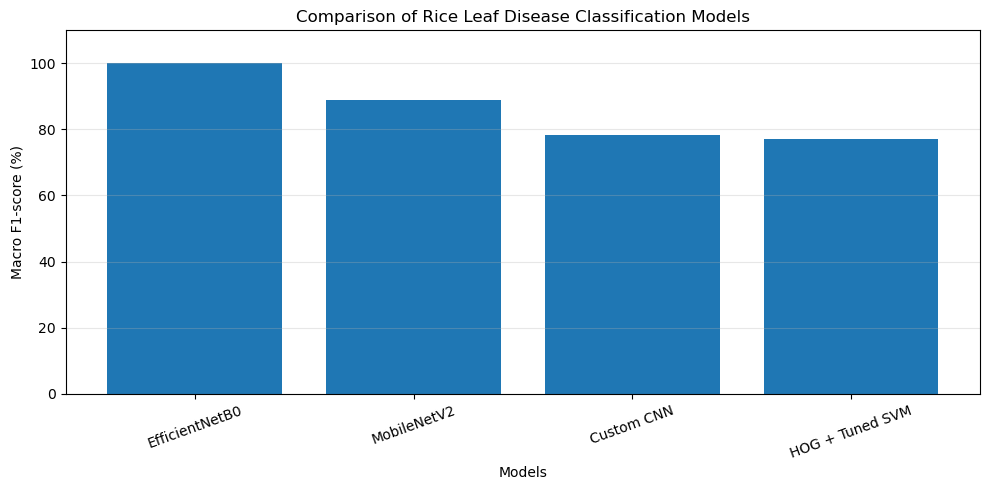

In [132]:
plt.figure(figsize=(10, 5))

plt.bar(
    model_comparison_final["Model"],
    model_comparison_final["Macro F1"]
)

plt.title("Comparison of Rice Leaf Disease Classification Models")
plt.xlabel("Models")
plt.ylabel("Macro F1-score (%)")
plt.ylim(0, 110)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [133]:
effnet_test_loss, effnet_test_accuracy = effnet_model.evaluate(
    X_test_effnet,
    y_test,
    verbose=0
)

print("EfficientNetB0 Test Accuracy:", effnet_test_accuracy)
print("EfficientNetB0 Test Loss:", effnet_test_loss)

EfficientNetB0 Test Accuracy: 0.8333333134651184
EfficientNetB0 Test Loss: 0.5473530292510986


In [134]:
effnet_test_probabilities = effnet_model.predict(
    X_test_effnet,
    verbose=0
)

y_test_effnet_pred = np.argmax(
    effnet_test_probabilities,
    axis=1
)

print("Actual Test Labels:", y_test)
print("Predicted Test Labels:", y_test_effnet_pred)

Actual Test Labels: [2 1 0 0 2 1 2 2 0 0 1 2 1 2 1 0 0 1]
Predicted Test Labels: [2 1 0 0 2 1 2 2 0 0 0 2 0 2 1 0 2 1]


In [135]:
print("EfficientNetB0 - Final Test Classification Report\n")

print(
    classification_report(
        y_test,
        y_test_effnet_pred,
        target_names=class_names,
        zero_division=0
    )
)

print("Test Macro Precision:",
      precision_score(y_test, y_test_effnet_pred,
                      average="macro", zero_division=0))

print("Test Macro Recall:",
      recall_score(y_test, y_test_effnet_pred,
                   average="macro", zero_division=0))

print("Test Macro F1:",
      f1_score(y_test, y_test_effnet_pred,
               average="macro", zero_division=0))

EfficientNetB0 - Final Test Classification Report

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.71      0.83      0.77         6
           Brown Spot       1.00      0.67      0.80         6
            Leaf Smut       0.86      1.00      0.92         6

             accuracy                           0.83        18
            macro avg       0.86      0.83      0.83        18
         weighted avg       0.86      0.83      0.83        18

Test Macro Precision: 0.8571428571428572
Test Macro Recall: 0.8333333333333334
Test Macro F1: 0.8307692307692308


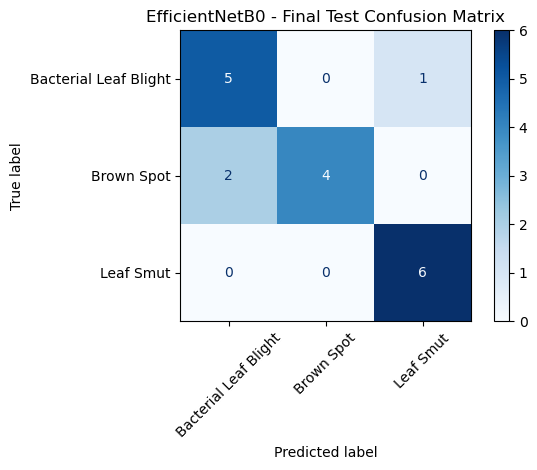

In [136]:
effnet_test_cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_effnet_pred,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

effnet_test_cm_display.ax_.set_title(
    "EfficientNetB0 - Final Test Confusion Matrix"
)

plt.tight_layout()
plt.show()

### Final Test Evaluation – EfficientNetB0

**Selected model:** EfficientNetB0

After comparing four classification approaches using the validation dataset, EfficientNetB0 was selected for final evaluation on the previously untouched test dataset.

**Final test results:**

| Metric | Result |
|---|---:|
| Accuracy | 83.33% |
| Macro Precision | 85.71% |
| Macro Recall | 83.33% |
| Macro F1-score | 83.08% |

**Class-wise evaluation:**

| Disease | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Bacterial Leaf Blight | 0.71 | 0.83 | 0.77 |
| Brown Spot | 1.00 | 0.67 | 0.80 |
| Leaf Smut | 0.86 | 1.00 | 0.92 |

**Test confusion matrix observations:**

1. Five out of six Bacterial Leaf Blight images were classified correctly.
2. Four out of six Brown Spot images were classified correctly.
3. All six Leaf Smut images were classified correctly.
4. Two Brown Spot images were misclassified as Bacterial Leaf Blight.
5. One Bacterial Leaf Blight image was misclassified as Leaf Smut.

**Validation versus test performance:**

EfficientNetB0 achieved 100% validation accuracy but 83.33% test accuracy. The difference indicates that perfect validation performance did not translate into perfect predictions on unseen test images.

**Conclusion:**

EfficientNetB0 is the leading candidate among the evaluated models based on validation performance, with a final test accuracy of 83.33% and macro F1-score of 83.08%. It demonstrated particularly strong detection of Leaf Smut. However, its performance on Brown Spot requires further investigation.

The dataset contains only 119 images, with six images per class in each validation and test split. Therefore, the results are preliminary and additional independent images are required before considering real-world deployment.

# Task 3 – Data Augmentation Analysis

## 1. Objective

The objective of this experiment was to investigate whether data augmentation could improve the generalization performance of the Custom CNN model by introducing controlled variations into the training images.

## 2. Augmentation techniques used

The following transformations were applied dynamically during training:

| Technique | Configuration | Purpose |
|---|---|---|
| Random Horizontal Flip | Horizontal flipping | Introduce variations in image orientation |
| Random Rotation | Factor = 0.03 | Introduce small rotational variations |
| Random Zoom | Factor = 0.05 | Introduce variations in image scale |
| Random Translation | Height and width factor = 0.03 | Introduce small positional variations |
| Fill Mode | Nearest | Fill empty areas created by transformations |

The augmentation layers were applied only during training. Validation and test images were not augmented.

## 3. Experimental comparison

The baseline Custom CNN was trained without augmentation. A separate controlled experiment was performed using the augmentation pipeline.

| Experiment | Validation Accuracy | Macro F1-score | Validation Loss |
|---|---:|---:|---:|
| Custom CNN without augmentation | 77.78% | 78.35% | 0.5565 |
| Custom CNN with controlled augmentation | 66.67% | 66.05% | 0.6590 |

## 4. Observations

1. The baseline Custom CNN achieved better validation accuracy and macro F1-score than the controlled augmented experiment.
2. The augmented experiment did not improve classification performance under the current experimental settings.
3. The dataset contains only 119 images, which may limit the diversity of examples available for learning.
4. Some transformations may alter the visual appearance or positional characteristics of disease symptoms.
5. The results indicate that augmentation does not automatically improve performance, particularly when working with a very small dataset.

An earlier exploratory augmented run achieved higher validation performance, but its initial learning rate differed from the intended configuration. Therefore, it was not treated as the controlled comparison.

## 5. Conclusion

The controlled experiment showed that the selected augmentation settings did not improve the Custom CNN's validation performance. The baseline model without augmentation performed better.

Further experiments using a larger and more diverse dataset, carefully selected transformations and systematic validation would be required to identify an effective augmentation strategy.

Data augmentation remains a useful technique, but its effectiveness depends on the dataset, transformation choices and model configuration.

# Task 4 – Challenges and Solutions Report

## 1. Dataset Size Limitation

**Challenge:**  
The dataset contained only 119 readable images instead of the 120 images mentioned in the assignment description. Each disease category had approximately 40 images.

**Technique used:**  
A stratified train-validation-test split was performed to preserve the representation of all three classes.

**Reason:**  
Stratification helps maintain class proportions across the three subsets. No artificial images were added to compensate for the missing image.

## 2. Different Image Dimensions and Aspect Ratios

**Challenge:**  
The original images had different widths, heights and aspect ratios. Directly feeding these images into a CNN would not be possible because the model requires a consistent input shape.

**Technique used:**  
All images were resized to 224 × 224 pixels while preserving their original aspect ratios. White padding was added where necessary.

**Reason:**  
This provides consistent input dimensions while reducing geometric distortion of the original leaf images.

## 3. Background Variation

**Challenge:**  
Some images contained white backgrounds, while others contained dark backgrounds or different amounts of background space. This variation could influence the features learned by a CNN.

**Technique used:**  
Background characteristics were examined through sample-image visualization and approximate border pixel analysis. All valid images were retained.

**Reason:**  
Removing background regions automatically could also remove useful leaf information. The analysis helped identify possible background-related bias without unnecessarily discarding images.

## 4. Similarity Between Disease Symptoms

**Challenge:**  
Some disease images showed overlapping visual characteristics, making classification between Bacterial Leaf Blight, Brown Spot and Leaf Smut difficult.

**Technique used:**  
Multiple classification approaches were evaluated, including HOG with SVM, a Custom CNN, MobileNetV2 and EfficientNetB0.

**Reason:**  
Comparing traditional image features, a CNN trained from scratch and pretrained CNN architectures helped identify an approach that performed better on the available data.

## 5. Small Dataset and Overfitting Risk

**Challenge:**  
The limited number of training images created a risk that models could learn specific training-image characteristics instead of general disease patterns.

**Technique used:**  
Dropout, Early Stopping and ReduceLROnPlateau were used in the CNN experiments. Transfer learning was initially performed with pretrained backbone layers frozen.

**Reason:**  
These techniques help control training and reduce unnecessary model complexity or continued training when validation performance stops improving.

## 6. Data Augmentation Did Not Improve Performance

**Challenge:**  
The controlled data augmentation experiment produced lower validation performance than the Custom CNN baseline.

**Technique used:**  
Horizontal flipping, small rotations, zooming and translations were evaluated in a separate controlled experiment.

**Reason:**  
The comparison helped determine whether the selected transformations were beneficial for the available dataset. The experiment showed that these settings did not improve performance under the current conditions.

## 7. Difference Between Validation and Test Performance

**Challenge:**  
EfficientNetB0 achieved 100% validation accuracy but only 83.33% accuracy on the independent test dataset.

**Technique used:**  
The dataset was separated into training, validation and test subsets. The test set was kept untouched during model selection.

**Reason:**  
This allowed the final model to be evaluated on images that were not used for training or validation-based model selection. The difference highlighted the importance of independent testing and the limitations of a small dataset.

## 8. Limited Computational Resources

**Challenge:**  
The project was executed in a Windows environment using CPU-based TensorFlow rather than native GPU acceleration.

**Technique used:**  
Transfer learning with pretrained CNN architectures was used, along with a fixed image size of 224 × 224 pixels and a batch size of 8.

**Reason:**  
Using pretrained feature extractors reduced the amount of model training required compared with training large CNN architectures entirely from scratch.

## 9. Assignment Description and Dataset Class-Name Inconsistency

**Challenge:**  
The assignment description mentioned Leaf Blast in one part, while the supplied dataset contained a Leaf Smut folder.

**Technique used:**  
The actual dataset folders were inspected, and the three classes present in the data were used for classification:
- Bacterial Leaf Blight
- Brown Spot
- Leaf Smut

**Reason:**  
The classification targets must correspond to the actual labelled dataset. The discrepancy should be documented rather than silently changing the dataset labels.

## Overall Conclusion

The project involved challenges related to limited data, image preprocessing, background variation, disease similarity, overfitting risk and model evaluation.

Image resizing with aspect-ratio preservation, stratified splitting, multiple model experiments, controlled augmentation, callbacks and independent test evaluation were used to address these challenges.

Although EfficientNetB0 achieved the strongest validation results, its 83.33% test accuracy indicates that further evaluation using a larger and more diverse dataset is necessary before real-world deployment.

# Final Project Conclusion and Production Recommendation

## 1. Project Overview

The objective of this project was to develop an image classification system to identify three major rice leaf diseases:

1. Bacterial Leaf Blight
2. Brown Spot
3. Leaf Smut

The project involved exploratory data analysis, image preprocessing, model development, data augmentation experiments, model comparison and final evaluation.

A total of 119 readable images were available in the supplied dataset.

## 2. Models Evaluated

Four classification approaches were implemented and compared:

- HOG + Tuned SVM: A traditional machine learning approach using Histogram of Oriented Gradients for image feature extraction.
- Custom CNN: A convolutional neural network trained from scratch.
- MobileNetV2: A pretrained CNN architecture using transfer learning.
- EfficientNetB0: A pretrained CNN architecture using transfer learning.

## 3. Validation Model Comparison

| Model | Validation Accuracy | Macro F1-score |
|---|---:|---:|
| HOG + Tuned SVM | 77.78% | 77.23% |
| Custom CNN | 77.78% | 78.35% |
| MobileNetV2 | 88.89% | 88.85% |
| EfficientNetB0 | 100.00% | 100.00% |

EfficientNetB0 achieved the highest validation performance among the evaluated models and was selected for final testing.

## 4. Final Test Evaluation

EfficientNetB0 achieved the following results on the independent test dataset:

| Metric | Test Result |
|---|---:|
| Accuracy | 83.33% |
| Macro Precision | 85.71% |
| Macro Recall | 83.33% |
| Macro F1-score | 83.08% |

The model correctly classified 15 out of 18 test images.

Leaf Smut achieved 100% recall, while Brown Spot achieved 67% recall. The confusion matrix showed that two Brown Spot images were classified as Bacterial Leaf Blight.

## 5. Data Augmentation Findings

Data augmentation was investigated using horizontal flipping, rotation, zooming and translation.

The controlled augmentation experiment achieved a validation accuracy of 66.67%, compared with 77.78% for the Custom CNN baseline without augmentation.

Therefore, the selected augmentation configuration did not improve model performance on the available dataset.

## 6. Production Recommendation

EfficientNetB0 is recommended as the leading candidate for further development because it achieved the highest validation performance and an independent test accuracy of 83.33%.

However, the current model should be considered an experimental prototype rather than a production-ready disease diagnosis system.

Before real-world deployment, the following improvements are recommended:

1. Collect a substantially larger dataset with more images for each disease category.
2. Include images captured under different lighting conditions, camera devices, backgrounds and field environments.
3. Investigate the confusion between Brown Spot and Bacterial Leaf Blight.
4. Evaluate model performance using repeated stratified cross-validation and additional independent test images.
5. Assess robustness and prediction reliability on real field images.

## 7. Overall Conclusion

This project demonstrated the application of image processing, traditional machine learning and deep learning techniques to rice leaf disease classification.

Among the four evaluated approaches, EfficientNetB0 achieved the best validation performance. Its final test accuracy of 83.33% demonstrates promising classification capability, although further validation using a larger and more diverse dataset is necessary.

The project also demonstrated that data augmentation does not always improve classification performance and that independent test evaluation is essential for understanding model generalization.

Overall, the project established a complete experimental workflow for rice leaf disease classification and identified EfficientNetB0 as the strongest candidate for future improvement and deployment testing.